# Детекція AI-текстів: LogReg · BiLSTM · DistilBERT

Датасет: DAIGT v2 (`thedrcat/daigt-v2-train-dataset`). Спліт робиться за темами (`prompt_name`), тому у val/test потрапляють теми, яких модель не бачила під час навчання.

- Усі параметри зібрані в **Experiments** (редагувати для нових експериментів)
- BiLSTM: базові параметри — `BILSTM`; набір експериментів — `BILSTM_EXPERIMENTS` (кожен запис — лише відмінності від бази); що запускати — `BILSTM_RUN`.
- DistilBERT: так само (`DISTILBERT`, `DISTILBERT_EXPERIMENTS`, `DISTILBERT_RUN`).
- Дані: `DATASETS` (параметри кожного датасету) і `DATA_SCENARIOS` (з чого складаються train/val/test); активний сценарій — `DATA_SCENARIO`. Можна брати один датасет, об'єднувати кілька або тренувати на одному та тестувати на іншому.

Результати кожного сценарію лежать окремо: `<WORK_DIR>/runs/<сценарій>/training_logs/<run_name>/` (`config.json` з повною конфігурацією і складом даних, `history.csv`, `group_metrics.csv`, `training.log`, `best_model.pt`, `run_summary.json`) та `<WORK_DIR>/runs/<сценарій>/test_results/<run_name>/`.

# Requirements

In [1]:
%pip install -q kagglehub datasets
!pip install transformers

In [2]:
import os, re, json, time, math, random, logging, unicodedata, zipfile, urllib.request
from collections import Counter
from dataclasses import dataclass, field, asdict, replace
from datetime import datetime
from itertools import product
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, log_loss
)

import joblib
import sklearn
from sklearn.metrics import log_loss

try:
    from tqdm.auto import tqdm
except ImportError:                       # tqdm немає — працюємо без прогрес-бару
    def tqdm(iterable=None, **kwargs):
        return iterable

# Google Drive (потрібен, щоб зберігати чекпоінти та ембединги між сесіями)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass  # не Colab

Mounted at /content/drive


# Configs

In [3]:
METRIC_NAMES = {"loss", "accuracy", "precision_ai", "recall_ai", "f1_ai", "macro_f1", "roc_auc"}
LOWER_IS_BETTER = {"loss"}


def _check(field_name, value, allowed):
    if value not in allowed:
        raise ValueError(f"{field_name}={value!r}: допустимі значення {sorted(allowed, key=str)}")


@dataclass
class DataConfig:
    """Загальні параметри спліту (для датасетів зі split="group" / "random")"""
    seed: int
    holdout_size: float          # частка (val + test) від датасету
    val_share: float             # частка val усередині holdout (решта test)


@dataclass
class DatasetSpec:
    """Підготовка одного з датасетів"""
    split: str                   # "group" (за колонкою group) | "random" (стратифікований) | "official" (готовий спліт автора)
    sample_size: Optional[int]   # None = весь датасет; число = стратифікована підвибірка
    ai_share: Optional[float]    # None = залишити як є; 0.5 = даунсемплінг більшого класу до 50/50
    strip_markdown: bool         # прибрати **, ##, плейсхолдери [Your Name], мітки «Title:» до очищення

    def __post_init__(self):
        _check("split", self.split, {"group", "random", "official"})
        if self.ai_share is not None and not 0 < self.ai_share < 1:
            raise ValueError(f"ai_share має бути в (0, 1) або None, а не {self.ai_share}")


@dataclass
class DataPlan:
    """Сценарій (з яких датасетів складається кожна вибірка)"""
    train: tuple
    val: tuple
    test: tuple
    full_if_single_role: bool    # датасет, що фігурує лише в одній ролі, береться цілком (train+val+test)
    # (за замовчуванням вимкнено)
    spec_overrides: dict = field(default_factory=dict)   # {датасет: {поле DatasetSpec: значення}} - лише для цього сценарію
    ai_share: Optional[float] = None                     # цільова частка AI у КОЖНІЙ вибірці (train/val/test) після збирання
    trim: tuple = ()

    def __post_init__(self):
        self.train, self.val, self.test = tuple(self.train), tuple(self.val), tuple(self.test)
        self.trim = tuple(self.trim)
        if not (self.train and self.val and self.test):
            raise ValueError("train, val і test мають містити хоча б один датасет")
        if self.ai_share is not None and not 0 < self.ai_share < 1:
            raise ValueError(f"ai_share має бути в (0, 1) або None, а не {self.ai_share}")


@dataclass
class LogRegConfig:
    ngram_range: tuple
    max_features: int
    min_df: int
    C: float
    max_iter: int
    seed: int


@dataclass
class TrainConfig:
    """Параметри навчання (BiLSTM і DistilBERT)"""
    optimizer: str               # "adam" (L2 на всі ваги) | "adamw" (без decay для bias/LayerNorm)
    lr: float
    weight_decay: float
    batch_size: int
    eval_batch_size: int
    grad_accum_steps: int        # ефективний batch = batch_size * grad_accum_steps
    grad_clip: float             # 0 = вимкнено
    n_epochs: int
    evals_per_epoch: int         # скільки разів за епоху рахувати val-метрики
    patience: int                # early stopping: лічильник оцінювань
    monitor: str                 # за якою val-метрикою вибирати чекпоінт і зупинятись
    scheduler: str               # "none" | "linear" (warmup + лінійне згасання до 0)
    warmup_ratio: float          # частка кроків на warmup (для scheduler="linear")
    amp: str                     # "none" | "fp16" | "bf16" | "auto" (bf16 на Ampere+, інакше fp16)
    seed: int

    def __post_init__(self):
        _check("optimizer", self.optimizer, {"adam", "adamw"})
        _check("scheduler", self.scheduler, {"none", "linear"})
        _check("amp", self.amp, {"none", "fp16", "bf16", "auto"})
        _check("monitor", self.monitor, METRIC_NAMES)
        if self.grad_accum_steps < 1 or self.evals_per_epoch < 1:
            raise ValueError("grad_accum_steps і evals_per_epoch мають бути ≥ 1")


@dataclass
class BiLSTMConfig(TrainConfig):
    # словник і послідовності
    vocab_max_size: int
    vocab_min_freq: int
    max_length: int
    # ембединги
    embedding: Optional[str]     # None (випадкові) | "glove" | "fasttext"
    embedding_dim: int           # використовується лише коли embedding=None
    freeze_embeddings: bool      # ігнорується коли embedding=None
    # архітектура
    hidden_size: int
    num_layers: int
    dropout: float               # перед лінійним шаром; між шарами LSTM - якщо num_layers > 1

    def __post_init__(self):
        super().__post_init__()
        _check("embedding", self.embedding, {None, "glove", "fasttext"})


@dataclass
class TransformerConfig(TrainConfig):
    model_name: str              # назва на HF
    max_length: int              # ≤ 512 для DistilBERT
    dropout: float               # DistilBertConfig.dropout
    attention_dropout: float     # DistilBertConfig.attention_dropout
    classifier_dropout: float    # DistilBertConfig.seq_classif_dropout


def make_grid(prefix, **axes):
    """make_grid("bilstm", hidden_size=[128, 256], dropout=[0.3, 0.5]): 4 експерименти {назва: {параметри}}."""
    names, values = list(axes), list(axes.values())
    grid = {}
    for combo in product(*values):
        overrides = dict(zip(names, combo))
        run_name = prefix + "__" + "__".join(f"{k}={v}" for k, v in overrides.items())
        grid[run_name] = overrides
    return grid


# Experiments (params)

Новий експеримент: додати рядок у BILSTM_EXPERIMENTS і вписати в BILSTM_RUN.

In [37]:
# Загальне
SMOKE_TEST = False     # True: перевірка пайплайну (3000 рядків, 1 епоха)

IN_COLAB = "COLAB_RELEASE_TAG" in os.environ
WORK_DIR = Path(os.environ.get(
    "AI_DETECT_WORK_DIR",
    "/content/drive/MyDrive/ai_detect" if IN_COLAB else "outputs",
))   # ембединги та результати

# дані
DATA = DataConfig(
    seed=42,
    holdout_size=0.30,       # 70% tr / 15% v / 15% test (за кількістю тем, тому реальні частки відрізняються)
    val_share=0.50,
)

DATASETS = {
    # "daigt": студентські есе (Kaggle DAIGT v2)
    "daigt": DatasetSpec(
        split="group",           # за темами (prompt_name)
        sample_size=None,
        ai_share=None,
        strip_markdown=False,
    ),
    # "defactify": новини NYT + 6 LLM (HF Rajarshi-Roy-research/Defactify_Text_Dataset), без промптів, є офіційний спліт.
    # На кожну статтю - 1 людський текст і 6 LLM-версій (AI ≈ 86%).
    # За замовчуванням вирівняти до 50/50
    "defactify": DatasetSpec(
        split="official",
        sample_size=None,        # напр. 20_000, щоб прискорити DistilBERT
        ai_share=0.5,            # None = лишити 86% AI; 0.6 = більше даних + все ще є баланс
        strip_markdown=True,
    ),
    # "defactify_prompts": ті самі статті у версії з промптами (HF gsingh1-py/train). НЕ поєднується з defactify (ті самі дані)
    "defactify_prompts": DatasetSpec(
        split="group",           # за промптом (стаття): всі 7 версій однієї статті потрапляють в один спліт
        sample_size=None,
        ai_share=0.5,
        strip_markdown=True,
    ),
}

# Сценарії використання датасетів в експериментах
DATA_SCENARIOS = {
    "daigt":                DataPlan(train=["daigt"],     val=["daigt"],     test=["daigt"],     full_if_single_role=True),
    "defactify":            DataPlan(train=["defactify"], val=["defactify"], test=["defactify"], full_if_single_role=True),
    "nyt_prompts":          DataPlan(train=["defactify_prompts"], val=["defactify_prompts"], test=["defactify_prompts"], full_if_single_role=True),

    # об'єднання (вибірки змішані з обох датасетів)
    "daigt_plus_defactify": DataPlan(
        train=["daigt", "defactify"],
        val=["daigt", "defactify"],
        test=["daigt", "defactify"],
        full_if_single_role=True,
        spec_overrides={"defactify": {"ai_share": None}},
        ai_share=0.55,
        trim=["defactify"],
        ),

    # train/val з одного, test з іншого
    "daigt_to_defactify":   DataPlan(train=["daigt"],     val=["daigt"],     test=["defactify"], full_if_single_role=True),
    "defactify_to_daigt":   DataPlan(train=["defactify"], val=["defactify"], test=["daigt"],     full_if_single_role=True),
}

# Logistic Regression (baseline)
LOGREG = LogRegConfig(
    ngram_range=(1, 2),
    max_features=50_000,
    min_df=2,
    C=1.0,
    max_iter=1000,
    seed=42,
)

# BiLSTM: базова конфігурація
BILSTM = BiLSTMConfig(
    # словник і послідовності
    vocab_max_size=30_000,       # 10_000 | 30_000 | 50_000
    vocab_min_freq=2,
    max_length=512,              # 512 | 1024
    # ембединги
    embedding=None,              # None | "glove" | "fasttext"
    embedding_dim=128,           # лише для embedding=None (для glove/fasttext розмірність 300)
    freeze_embeddings=False,
    # архітектура
    hidden_size=128,
    num_layers=1,
    dropout=0.3,
    # навчання
    optimizer="adam",
    lr=1e-3,
    weight_decay=1e-4,
    batch_size=64,
    eval_batch_size=64,
    grad_accum_steps=1,
    grad_clip=1.0,
    n_epochs=30,
    evals_per_epoch=1,
    patience=10,
    monitor="loss",
    scheduler="none",
    warmup_ratio=0.0,
    amp="none",
    seed=42,
)

# Експерименти: {назва: {відмінності від baseline BILSTM}}
BILSTM_EXPERIMENTS = {
    # "bilstm_random_baseline":    {},

    # "bilstm_vocab50k":           dict(vocab_max_size=50_000),
    # "bilstm_len1024":            dict(max_length=1024),
    # "bilstm_vocab50k_len1024":   dict(vocab_max_size=50_000, max_length=1024),

    "bilstm_glove_frozen":       dict(embedding="glove",    freeze_embeddings=True, vocab_max_size=50_000, max_length=1024),
    "bilstm_glove_finetuned":    dict(embedding="glove",    freeze_embeddings=False, vocab_max_size=50_000, max_length=1024),
    # "bilstm_glove_finetuned_lr_3e-4":    dict(embedding="glove",    freeze_embeddings=False, vocab_max_size=50_000, max_length=1024, lr=3e-4),

    "bilstm_fasttext_frozen":    dict(embedding="fasttext", freeze_embeddings=True, vocab_max_size=50_000, max_length=1024),
    "bilstm_fasttext_finetuned": dict(embedding="fasttext", freeze_embeddings=False, vocab_max_size=50_000, max_length=1024),
    # "bilstm_fasttext_finetuned_lr_3e-4": dict(embedding="fasttext", freeze_embeddings=False, vocab_max_size=50_000, max_length=1024, lr=3e-4),

    # інші комбінації:
    # "bilstm_h256_2layers":    dict(hidden_size=256, num_layers=2, dropout=0.4),
}

# Grid - усі комбінації (2×2 = 4 запуски):
# BILSTM_EXPERIMENTS.update(make_grid("bilstm_grid", hidden_size=[128, 256], dropout=[0.3, 0.5]))

DATA_SCENARIO = "daigt_plus_defactify" # використовується зараз (daigt | defactify | daigt_plus_defactify)

BILSTM_RUN = list(BILSTM_EXPERIMENTS) # [] # назви моделей
# запустити все: list(BILSTM_EXPERIMENTS)

# DistilBERT: базова конфігурація
DISTILBERT = TransformerConfig(
    model_name="distilbert-base-cased",
    max_length=512,              # максимум для DistilBERT
    dropout=0.1,
    attention_dropout=0.1,
    classifier_dropout=0.2,
    # навчання
    optimizer="adamw",
    lr=2e-5,
    weight_decay=0.01,
    batch_size=16,
    eval_batch_size=64,
    grad_accum_steps=2,          # ефективний batch = 32
    grad_clip=1.0,
    n_epochs=3,
    evals_per_epoch=2,           # val 2 раза за епоху
    patience=3,                  # 3 оцінювання поспіль без покращення (= 1.5 епохи)
    monitor="loss",              # (як для BiLSTM) "loss" / "macro_f1" / "roc_auc"
    scheduler="linear",
    warmup_ratio=0.1,
    amp="auto",
    seed=42,
)

DISTILBERT_EXPERIMENTS = {
    "distilbert_cased":   {},
    "distilbert_uncased": dict(model_name="distilbert-base-uncased"),
    "distilbert_lr3e-5":  dict(lr=3e-5),
    "distilbert_lr5e-5":  dict(lr=5e-5),
    "distilbert_len256":  dict(max_length=256, batch_size=32, grad_accum_steps=1),
}
# DISTILBERT_EXPERIMENTS.update(make_grid("distilbert_grid", lr=[2e-5, 3e-5], n_epochs=[2, 3]))

DISTILBERT_RUN = list(DISTILBERT_EXPERIMENTS) # ["distilbert_cased"]


# Утиліти

In [38]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROLES = ("train", "val", "test")
SMOKE_ROWS = 3000

RUNS_ROOT = (WORK_DIR / "_smoke" if SMOKE_TEST else WORK_DIR) / "runs"


def scenario_dir(name):
    return RUNS_ROOT / name


OUT_DIR = scenario_dir(DATA_SCENARIO)          # перевизначається в use_scenario()
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE, "| OUT_DIR:", OUT_DIR, "| SMOKE_TEST:", SMOKE_TEST)

GROUP_COLUMNS = ["dataset", "prompt_name", "source"]    # розбивка метрик
MAX_PRINT_GROUPS = 20

CACHE = {"bilstm": {}, "emb": {}, "tok": {}}   # скидається при кожному новому сценарії
DATA_CACHE = {"raw": {}, "parts": {}}          # завантажені датасети живуть увесь сеанс


def print_group_table(group_metrics, title):
    print(f"\n=== {title} ===")
    if len(group_metrics) > MAX_PRINT_GROUPS:
        print(f"(показано {MAX_PRINT_GROUPS} найгірших за f1_ai із {len(group_metrics)}; повна таблиця — у CSV)")
    print(group_metrics.head(MAX_PRINT_GROUPS).round(4).to_string(index=False))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def apply_smoke(cfg):
    """У режимі SMOKE_TEST робить конфіг мінімальним"""
    if not SMOKE_TEST:
        return cfg
    return replace(cfg, n_epochs=1, evals_per_epoch=1, max_length=min(cfg.max_length, 128))


def make_cfg(base, overrides):
    """Базовий конфіг + відмінності експерименту (+ smoke-режим). Невідомий параметр: TypeError"""
    return apply_smoke(replace(base, **overrides))


def resolve_amp_dtype(mode, device):
    if device.type != "cuda" or mode == "none":
        return None
    if mode == "auto":
        # bf16 — лише на Ampere+ (compute capability ≥ 8); на T4 швидший fp16
        return torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    return {"fp16": torch.float16, "bf16": torch.bfloat16}[mode]


def autocast_ctx(device, amp_dtype):
    return torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=amp_dtype is not None)


def count_parameters(model, trainable_only=True):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


def _json_default(obj):
    if hasattr(obj, "item"):          # numpy-скаляри
        return obj.item()
    raise TypeError(f"Not JSON serializable: {type(obj)}")


def write_summary(run_dir, updates):
    """Дописує/оновлює run_summary.json (його читає collect_results)"""
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    path = run_dir / "run_summary.json"
    data = json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}
    data.update(updates)
    path.write_text(json.dumps(data, indent=2, ensure_ascii=False, default=_json_default), encoding="utf-8")


def make_loader(dataset, batch_size, shuffle, collate_fn, seed):
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collate_fn,
        generator=generator if shuffle else None,
        pin_memory=torch.cuda.is_available(),
    )


Device: cuda | OUT_DIR: /content/drive/MyDrive/ai_detect/runs/daigt_plus_defactify | SMOKE_TEST: False


# Data

Схема датасету (для зручності при додаванні нових датасетів)

| колонка | зміст |
|---|---|
| `text`, `label` | текст і мітка (1 = AI, 0 = людина) |
| `prompt_name` | тема для звітів «метрики за темами» |
| `source` | хто написав: `persuade_corpus`, назва LLM тощо |
| `dataset` | з якого датасету рядок — потрібно для розбивки метрик у змішаних сценаріях |
| `group` | службова: рядки з однаковим `group` не розриваються між train/val/test |

**Датасети**
- `daigt` — студентські есе; групи = теми (`prompt_name`)
- `defactify` — новини NYT, 1 людський текст + 6 LLM-версій на статтю. Промптів немає, але є офіційний спліт (використовується). `source` = модель (`Label_B`).
- `defactify_prompts` — train-частина `defactify` в іншому форматі з колонкою `prompt`. Вибирати коли потрібен спліт за промптами.

Можна вибирати лише один із `defactify` та `defactify_prompts`.

Відсікаються перетини між train/val/test.

З `defactify*` прибрано повідомлення про помилку API (Error communicating with OpenAI) (в датасеті були помічені як AI).

In [39]:
# Приведення сирих датасетів до єдиної схеми

def normalize_source_name(name):
    """
    'Human_Story' = 'human'
    'accounts/yi-01-ai/models/yi-large' = 'yi-large'
    'GPT_4-o' = 'gpt-4o'
    """
    name = str(name).split("/")[-1].lower().replace("_", "-")
    if name.startswith("human"):
        return "human"
    return {"gpt-4-o": "gpt-4o"}.get(name, name)


GENERATION_ERROR_RE = r"Error communicating with OpenAI|HTTPSConnectionPool|Max retries exceeded"


def drop_generation_errors(df, tag):
    mask = df["text"].astype(str).str.contains(GENERATION_ERROR_RE, regex=True, na=False)
    if mask.any():
        print(f"{tag}: прибрано {int(mask.sum())} повідомлень про помилку API")
    return df[~mask].copy()


def standardize_daigt(raw):
    out = raw[["text", "label", "prompt_name", "source"]].copy()
    out["dataset"] = "daigt"
    out["group"] = out["prompt_name"]
    return out


def standardize_defactify(raw):
    """Defactify_Text_Dataset:
       Text,
       Label_A (0 = людина, 1 = AI),
       Label_B (джерело)
       + колонка split (train/validation/test).
       """
    out = pd.DataFrame({
        "text": raw["Text"],
        "label": raw["Label_A"],
        "prompt_name": "nyt_news", # в цьому датасеті немає промптів
        "source": "nyt/" + raw["Label_B"].map(normalize_source_name),
        "dataset": "defactify",
        "group": None,
        "split": raw["split"],
    })
    return drop_generation_errors(out, "defactify").reset_index(drop=True)


def standardize_defactify_prompts(raw):
    """
    gsingh1-py/train:
       широкий формат: prompt + по колонці на людський текст і на кожну модель
       convert to long (standart) format
    """
    if "prompt" not in raw.columns:
        raise KeyError(f"Очікувалась колонка 'prompt'; є: {list(raw.columns)}")
    text_cols = [c for c in raw.columns if c != "prompt"]
    long = raw.melt(id_vars="prompt", value_vars=text_cols, var_name="src", value_name="text")
    long = long.dropna(subset=["text", "prompt"])
    src = long["src"].map(normalize_source_name)
    out = pd.DataFrame({
        "text": long["text"],
        "label": (src != "human").astype(int),
        "prompt_name": "nyt_news",           # 7k заголовків = "nyt_news", щоб не генерувався звіт за 7тис. промптами
        "source": "nyt/" + src,
        "dataset": "defactify_prompts",
        "group": long["prompt"],             # промпти для спліту (різні промпти в train|val|test)
    })
    return drop_generation_errors(out, "defactify_prompts").reset_index(drop=True)


def download_daigt():
    import kagglehub
    path = kagglehub.dataset_download("thedrcat/daigt-v2-train-dataset")
    return pd.read_csv(os.path.join(path, "train_v2_drcat_02.csv"))


def download_defactify():
    from datasets import load_dataset
    frames = []
    for split_name, part in load_dataset("Rajarshi-Roy-research/Defactify_Text_Dataset").items():
        frame = part.to_pandas()
        frame["split"] = split_name
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)


def download_defactify_prompts():
    from datasets import load_dataset
    return load_dataset("gsingh1-py/train", split="train").to_pandas()


# назва: (завантаження, приведення до схеми)
# Новий датасет = ще один рядок тут + запис у DATASETS

DATASET_LOADERS = {
    "daigt": (download_daigt, standardize_daigt),
    "defactify": (download_defactify, standardize_defactify),
    "defactify_prompts": (download_defactify_prompts, standardize_defactify_prompts),
}
KNOWN_SAME_SOURCE = [{"defactify", "defactify_prompts"}] # заборонити спільне використ.


In [40]:
class DataPreparation:
    """Очищення, підвибірка і спліт датасету (приведеного до єдиної схеми)"""

    def __init__(self, spec: DatasetSpec, cfg: DataConfig):
        self.spec = spec
        self.cfg = cfg
        self.SEED = cfg.seed
        self.n_total = None

    # очищення тексту
    @staticmethod
    def strip_markdown(text):
        """Прибирає розмітку й шаблонні артефакти LLM. Ставити до згортання пробілів (потрібні переноси рядків)"""
        text = re.sub(r"(?m)^[ \t]{0,3}#{1,6}[ \t]*", "", text)        # заголовки ##
        text = re.sub(r"(?m)^[ \t]*([-*_][ \t]*){3,}$", "", text)      # ---
        text = re.sub(r"\*{1,3}|_{2,}", "", text)                      # форматування **т**, *т*, __т__
        text = re.sub(r"\[[^\[\]]{1,40}\]", "", text)                  # плейсхолдер [Your Name], [Date]
        text = re.sub(r"(?mi)^[ \t]*(title|subtitle|headline|byline|introduction|conclusion):[ \t]*", "", text)
        return text

    @staticmethod
    def preprocess_text(text, strip_md=False):
        if not isinstance(text, str):
            return ""

        if strip_md:
            text = DataPreparation.strip_markdown(text)

        # Unicode Normalization
        text = unicodedata.normalize("NFKC", text)

        # HTML tags <br>, <div>, <p>
        text = re.sub(r"<.*?>", "", text)

        # Newlines and Escape Characters
        text = re.sub(r"[\r\n\t]+", " ", text)
        text = text.replace("\\", "")
        text = text.replace("[", "")
        text = text.replace("]", "")

        # collapse multiple spaces into one
        text = re.sub(r"\s+", " ", text).strip()

        # links (http, https, www)
        text = re.sub(r"http\S+|www\.\S+", "", text)

        return text

    def clean_dataset(self, df):
        # Видаляємо рядки без тексту або мітки
        df = df.dropna(subset=["text", "label"]).copy()

        # Нормалізуємо пробіли на початку та в кінці
        df["text"] = df["text"].astype(str).str.strip()

        # Видаляємо порожні тексти
        df = df[df["text"].ne("")].copy()

        # Переконуємося, що мітки мають значення 0 або 1
        df["label"] = df["label"].astype(int)
        assert set(df["label"].unique()) == {0, 1}

        # Знаходимо однакові тексти з конфліктними мітками
        label_counts = df.groupby("text")["label"].nunique()
        conflicting_texts = label_counts[label_counts > 1].index
        if len(conflicting_texts) > 0:
            print("Texts with conflicting labels:", len(conflicting_texts))

        # Виключаємо неоднозначні приклади
        df = df[~df["text"].isin(conflicting_texts)].copy()

        # Видаляємо точні дублікати тексту
        df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

        return df

    # баланс класів, підвибірка, спліт
    def _partition_keys(self, df):
        """Для офіційного спліту баланс і підвибірку робимо всередині кожної частини, щоб не зсувати її розмір"""
        if self.spec.split == "official" and "split" in df.columns:
            return df["split"]
        return pd.Series("all", index=df.index)

    def rebalance(self, df):
        target = self.spec.ai_share
        if target is None:
            return df

        kept = []
        for _, part in df.groupby(self._partition_keys(df)):
            ai, human = part[part["label"] == 1], part[part["label"] == 0]
            if len(ai) / len(part) > target:         # багато AI = downsample AI
                ai = ai.sample(n=min(len(ai), int(round(len(human) * target / (1 - target)))), random_state=self.SEED)
            else:                                    # багато людських текстів = downsample
                human = human.sample(n=min(len(human), int(round(len(ai) * (1 - target) / target))), random_state=self.SEED)
            kept.append(pd.concat([human, ai]))

        out = pd.concat(kept).reset_index(drop=True)
        print(f"ai_share={target}: {len(df)} -> {len(out)} рядків (частка AI {df['label'].mean():.1%} -> {out['label'].mean():.1%})")
        return out

    def sample_dataset(self, df, sample_size):
        if sample_size is None or sample_size >= len(df):
            if sample_size is not None and sample_size > len(df):
                print(f"sample_size={sample_size} більший за датасет ({len(df)}); беремо весь датасет")
            df_sample = df
        elif self.spec.split == "official" and "split" in df.columns:
            frac = sample_size / len(df)
            df_sample = df.groupby(["split", "label"]).sample(frac=frac, random_state=self.SEED)
        else:
            df_sample, _ = train_test_split(
                df, train_size=sample_size, stratify=df["label"], random_state=self.SEED
            )

        df_sample = df_sample.sample(frac=1, random_state=self.SEED).reset_index(drop=True)

        print("Selected sample size:", len(df_sample))
        print("\nClass distribution:")
        print(df_sample["label"].value_counts())
        print(df_sample["label"].value_counts(normalize=True).round(3))

        return df_sample

    @staticmethod
    def _show_groups(name, groups):
        groups = sorted(groups)
        shown = groups if len(groups) <= 20 else groups[:5] + ["..."]
        print(f"{name} groups ({len(groups)}):", shown)

    def _group_split(self, df):
        gss_train_temp = GroupShuffleSplit(
            n_splits=1, test_size=self.cfg.holdout_size, random_state=self.SEED
        )
        gss_val_test = GroupShuffleSplit(
            n_splits=1, test_size=1 - self.cfg.val_share, random_state=self.SEED
        )

        train_idx, temp_idx = next(gss_train_temp.split(df, df["label"], groups=df["group"]))
        group_train = df.iloc[train_idx].copy()
        group_temp = df.iloc[temp_idx].copy()

        val_idx, test_idx = next(gss_val_test.split(group_temp, group_temp["label"], groups=group_temp["group"]))
        group_val = group_temp.iloc[val_idx].copy()
        group_test = group_temp.iloc[test_idx].copy()

        self._show_groups("Train", group_train["group"].unique())
        self._show_groups("Val", group_val["group"].unique())
        self._show_groups("Test", group_test["group"].unique())

        print("\nTrain label distribution:")
        print(group_train["label"].value_counts(normalize=True).sort_index())

        return group_train, group_val, group_test

    def split_dataset(self, df_sample):
        kind = self.spec.split
        if kind == "official":
            names = {"train": "train", "validation": "val", "val": "val", "test": "test"}
            role = df_sample["split"].map(names)
            if role.isna().any():
                raise ValueError(f"Невідомі назви частин у колонці split: {sorted(df_sample.loc[role.isna(), 'split'].unique())}")
            train_df, val_df, test_df = (df_sample[role == r] for r in ROLES)
        elif kind == "group":
            if df_sample["group"].isna().any():
                raise ValueError("split='group' потребує непорожньої колонки group")
            train_df, val_df, test_df = self._group_split(df_sample)
        else:
            train_df, temp_df = train_test_split(
                df_sample, test_size=self.cfg.holdout_size,
                stratify=df_sample["label"], random_state=self.SEED,
            )
            val_df, test_df = train_test_split(
                temp_df, test_size=1 - self.cfg.val_share,
                stratify=temp_df["label"], random_state=self.SEED,
            )

        # Порядок рядків у df має збігатися з порядком передбачень (скинути індекси)
        train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))
        print("Sample size (after splitting):", len(train_df) + len(val_df) + len(test_df))
        return train_df, val_df, test_df

    # перевірки
    def check_dataset(self, train_df, val_df, test_df):
        for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
            print(f"\n{name}: {len(part)} rows")
            print(part["label"].value_counts().sort_index())
            print(part["label"].value_counts(normalize=True).sort_index().round(3))

        # відсутність перетину текстів
        train_texts, val_texts, test_texts = set(train_df["text"]), set(val_df["text"]), set(test_df["text"])
        assert train_texts.isdisjoint(val_texts)
        assert train_texts.isdisjoint(test_texts)
        assert val_texts.isdisjoint(test_texts)
        assert len(train_df) + len(val_df) + len(test_df) == self.n_total

        print("\nAll checks passed!")

    def distribution_check(self, df):
        # 1. Розподіл класів у різних джерелах
        print("=== SOURCE × LABEL ===")
        print(pd.crosstab(df["source"], df["label"], normalize="index").round(3))

        print("\n=== SOURCE COUNTS ===")
        print(pd.crosstab(df["source"], df["label"]))

        # 2. Розподіл класів за промптами
        print("\n=== PROMPT_NAME × LABEL ===")
        print(pd.crosstab(df["prompt_name"].fillna("<missing>"), df["label"], normalize="index").round(3))

        print("\n=== PROMPT COUNTS ===")
        print(pd.crosstab(df["prompt_name"].fillna("<missing>"), df["label"]))

        # 3. Кількість символів і слів
        df["char_count"] = df["text"].str.len()
        df["word_count"] = df["text"].str.split().str.len()
        print(df.groupby("label")[["char_count", "word_count"]].describe())

        plt.figure(figsize=(9, 5))
        for label, name in [(0, "Human"), (1, "AI")]:
            values = df.loc[df["label"] == label, "word_count"]
            plt.hist(values.clip(upper=2000), bins=50, alpha=0.5, density=True, label=name)
        plt.xlabel("Number of words (capped at 2000)")
        plt.ylabel("Density")
        plt.title("Text length distribution by class")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # головний метод
    def prepare_dataset(self, dataset_df, dataset_check=True):
        df = dataset_df.copy()                       # вихідний датафрейм не змінюється
        df["text"] = df["text"].apply(lambda t: self.preprocess_text(t, self.spec.strip_markdown))
        cleaned_df = self.clean_dataset(df)
        cleaned_df = self.rebalance(cleaned_df)

        df_sample = self.sample_dataset(cleaned_df, self.spec.sample_size)
        self.n_total = len(df_sample)
        train_df, val_df, test_df = self.split_dataset(df_sample)

        if dataset_check:
            self.distribution_check(cleaned_df)
            self.check_dataset(train_df, val_df, test_df)

        return train_df, val_df, test_df

## Збирання сценарію

In [41]:
class Splits(dict):
    """{'train': df, 'val': df, 'test': df} + .info (опис сценарію зберігається в config.json кожного запуску)"""
    info = None


def prepare_dataset_parts(name, spec):
    """Три частини одного датасету (train/val/test). Кешується: повторні сценарії не перераховують."""
    key = (name, json.dumps(asdict(spec), sort_keys=True), json.dumps(asdict(DATA), sort_keys=True))
    if key not in DATA_CACHE["parts"]:
        if name not in DATA_CACHE["raw"]:
            download, standardize = DATASET_LOADERS[name]
            DATA_CACHE["raw"][name] = standardize(download())
        parts = DataPreparation(spec, DATA).prepare_dataset(DATA_CACHE["raw"][name], dataset_check=False)
        DATA_CACHE["parts"][key] = dict(zip(ROLES, parts))
    return DATA_CACHE["parts"][key]


def remove_text_overlaps(splits):
    """Однаковий текст не може бути одночасно в train і val/test: пріоритет test > val > train."""
    test_texts, val_texts = set(splits["test"]["text"]), set(splits["val"]["text"])
    drop_train = splits["train"]["text"].isin(test_texts | val_texts)
    drop_val = splits["val"]["text"].isin(test_texts)
    if drop_train.any() or drop_val.any():
        print(f"Перетини текстів: прибрано {int(drop_train.sum())} з train і {int(drop_val.sum())} з val")
    splits["train"] = splits["train"][~drop_train].reset_index(drop=True)
    splits["val"] = splits["val"][~drop_val].reset_index(drop=True)


def rebalance_role(df, target, trim, seed, role):
    """Доводить частку AI у вибірці до target, прибираючи випадкові рядки лише з датасетів trim (порожній trim = з будь-яких)."""
    n_ai = int((df["label"] == 1).sum())
    n_human = len(df) - n_ai
    share = n_ai / len(df)
    if abs(share - target) < 0.001:
        return df

    flexible = df["dataset"].isin(trim) if trim else pd.Series(True, index=df.index)
    if share > target:                                   # забагато AI - прибираємо AI
        n_drop = n_ai - int(round(n_human * target / (1 - target)))
        pool, what = df[flexible & (df["label"] == 1)], "AI"
    else:                                                # забагато людських - прибираємо людські
        n_drop = n_human - int(round(n_ai * (1 - target) / target))
        pool, what = df[flexible & (df["label"] == 0)], "людських"
    n_drop = max(0, n_drop)

    if n_drop > len(pool):
        print(f"  {role}: у дозволеному пулі лише {len(pool)} {what} текстів, треба прибрати {n_drop}; ціль недосяжна, прибрано максимум")
        n_drop = len(pool)

    out = df.drop(pool.sample(n=n_drop, random_state=seed).index).reset_index(drop=True)
    print(f"  {role}: {len(df)} → {len(out)} рядків, частка AI {share:.1%} → {out['label'].mean():.1%} (прибрано {n_drop} {what})")
    return out


def describe_splits(scenario, plan, splits):
    rows = []
    for role in ROLES:
        df = splits[role]
        for dataset, part in df.groupby("dataset"):
            rows.append({"role": role, "dataset": dataset, "rows": len(part), "ai_share": round(float(part["label"].mean()), 3)})
        rows.append({"role": role, "dataset": "— усього —", "rows": len(df), "ai_share": round(float(df["label"].mean()), 3)})
    table = pd.DataFrame(rows)
    print(f"\nСценарій {scenario!r}:")
    print(table.to_string(index=False))
    return {"scenario": scenario, "plan": asdict(plan), "sizes": rows}


def build_splits(scenario):
    plan = DATA_SCENARIOS[scenario]
    used = sorted(set(plan.train) | set(plan.val) | set(plan.test))

    unknown = [n for n in used if n not in DATASETS]
    if unknown:
        raise KeyError(f"Невідомі датасети {unknown}. Є в DATASETS: {list(DATASETS)}")
    for pair in KNOWN_SAME_SOURCE:
        if pair <= set(used):
            raise ValueError(f"{sorted(pair)} — це два формати одних і тих самих статей; поєднувати їх не можна (витік даних).")

    roles_of = {n: [r for r in ROLES if n in getattr(plan, r)] for n in used}

    for label, names in [("spec_overrides", plan.spec_overrides), ("trim", plan.trim)]:
        stray = set(names) - set(used)
        if stray:
            raise ValueError(f"{label}: {sorted(stray)} не беруть участі в сценарії {scenario!r} (є {used})")

    parts = {}
    for name in used:
        spec = replace(DATASETS[name], **plan.spec_overrides.get(name, {}))
        if SMOKE_TEST:
            spec = replace(spec, sample_size=min(spec.sample_size or SMOKE_ROWS, SMOKE_ROWS))
        print(f"\n{'─' * 25} {name} {'─' * 25}")
        parts[name] = prepare_dataset_parts(name, spec)

    splits = Splits()
    for role in ROLES:
        frames = []
        for name in getattr(plan, role):
            if plan.full_if_single_role and len(roles_of[name]) == 1:
                frames.append(pd.concat(parts[name].values(), ignore_index=True))     # датасет бере участь лише тут → цілком
            else:
                frames.append(parts[name][role])
        splits[role] = pd.concat(frames, ignore_index=True).drop_duplicates(subset="text").reset_index(drop=True)

    remove_text_overlaps(splits)

    if plan.ai_share is not None:
        print(f"\nВирівнювання вибірок до частки AI ≈ {plan.ai_share:.0%} (прибираємо з: {list(plan.trim) or 'будь-яких датасетів'})")
        for role in ROLES:
            splits[role] = rebalance_role(splits[role], plan.ai_share, plan.trim, DATA.seed, role)

    splits.info = describe_splits(scenario, plan, splits)
    return splits


def use_scenario(name):
    """Збирає сценарій і робить його активним (SPLITS, train_df/val_df/test_df, OUT_DIR)."""
    global OUT_DIR, SPLITS, train_df, val_df, test_df
    if name not in DATA_SCENARIOS:
        raise KeyError(f"Невідомий сценарій {name!r}. Є: {list(DATA_SCENARIOS)}")
    SPLITS = build_splits(name)
    train_df, val_df, test_df = SPLITS["train"], SPLITS["val"], SPLITS["test"]
    OUT_DIR = scenario_dir(name)
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    for cache in CACHE.values():
        cache.clear()                     # словники/токенізація залежать від train
    print("\nOUT_DIR:", OUT_DIR)
    return SPLITS

# use_scenario(name):

# підготовка датасетів, вказаних для використання (у сценарії)
# датасети кешуються на сеанс
# розділяє train/val/test, прибирає перетини, друкує склад і перемикає OUT_DIR на папку цього сценарію


In [42]:
use_scenario(DATA_SCENARIO)



───────────────────────── daigt ─────────────────────────
Using Colab cache for faster access to the 'daigt-v2-train-dataset' dataset.
Selected sample size: 44862

Class distribution:
label
0    27365
1    17497
Name: count, dtype: int64
label
0    0.61
1    0.39
Name: proportion, dtype: float64
Train groups (10): ['Car-free cities', 'Cell phones at school', 'Community service', 'Distance learning', 'Driverless cars', 'Exploring Venus', 'Facial action coding system', 'Mandatory extracurricular activities', 'Seeking multiple opinions', 'The Face on Mars']
Val groups (2): ['"A Cowboy Who Rode the Waves"', 'Phones and driving']
Test groups (3): ['Does the electoral college work?', 'Grades for extracurricular activities', 'Summer projects']

Train label distribution:
label
0    0.583128
1    0.416872
Name: proportion, dtype: float64
Sample size (after splitting): 44862

───────────────────────── defactify ─────────────────────────
defactify: прибрано 410 повідомлень про помилку API
Select

{'train':                                                     text  label  \
 0      Here are some relevant talking points to discu...      1   
 1      This job is an opportunity for me to showcase ...      1   
 2      Imagine you need to get advice for an issue yo...      0   
 3      Venus is a planet what belong the System Solar...      0   
 4      Eliminating car usage can benefit ones life in...      0   
 ...                                                  ...    ...   
 57717  Newsletter Cooking A Pantry Pasta Perfect for ...      0   
 57718  Every Time She Hit It Big, Something Knocked H...      1   
 57719  SEE FULL RESULTS AND MAPS FROM THE 2022 INDIAN...      1   
 57720  As the sun sets on the 2022 New York elections...      1   
 57721  new video loaded:Above the Keystone Pipeline O...      0   
 
                        prompt_name                source    dataset  \
 0        Seeking multiple opinions         chat_gpt_moth      daigt   
 1      Facial action coding 

### Перевірка (shortcut)

In [43]:
# Перевірка того, чи можна відрізнити клас за самим форматуванням і довжиною
# Логістична регресія на п'яти ознаках:
# 1. кількість *, #, _,
# 2. довжина тексту
# 3. чи починається текст з "Title:"

# strip_markdown=True прибирає ці ознаки, лишається лише довжина тексту
# (моделі розпізнають стиль, а не розмітку)

def format_probe(splits):
    """ROC-AUC на val за ознаками формату (навчання на train). По кожному датасету окремо."""
    def feats(df):
        t = df["text"].astype(str)
        return pd.DataFrame({
            "stars": t.str.count(r"\*"),
            "hashes": t.str.count("#"),
            "underscores": t.str.count("_"),
            "length": t.str.len(),
            "starts_title": t.str.lower().str.startswith("title:").astype(int),
        })

    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
    probe.fit(feats(splits["train"]), splits["train"]["label"])

    for dataset, part in splits["val"].groupby("dataset"):
        if part["label"].nunique() < 2:
            continue
        auc = roc_auc_score(part["label"], probe.predict_proba(feats(part))[:, 1])
        print(f"{dataset:20s} ROC-AUC (лише формат і довжина): {auc:.3f}")


format_probe(SPLITS)

daigt                ROC-AUC (лише формат і довжина): 0.472
defactify            ROC-AUC (лише формат і довжина): 0.467


# Метрики, тренування, тестування

In [44]:
class Metrics:
    def calculate_metrics(self, y_true, y_pred, y_prob):
        """Загальні метрики для бінарної класифікації."""
        metrics = {
            "accuracy": accuracy_score(y_true, y_pred),
            "precision_ai": precision_score(y_true, y_pred, zero_division=0),
            "recall_ai": recall_score(y_true, y_pred, zero_division=0),
            "f1_ai": f1_score(y_true, y_pred, zero_division=0),
            "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        }

        # ROC-AUC не визначений, якщо у вибірці лише один клас.
        metrics["roc_auc"] = (
            roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan
        )
        return metrics

    def calculate_group_metrics(self, results_df, group_column):
        """Метрики окремо для кожного prompt_name або source."""
        rows = []
        for group_value, group in results_df.groupby(group_column, dropna=False):
            y_true = group["label"].to_numpy(dtype=int)
            y_pred = group["y_pred"].to_numpy(dtype=int)
            y_prob = group["y_prob"].to_numpy(dtype=float)

            row = {group_column: group_value, "n": len(group)}
            row.update(self.calculate_metrics(y_true, y_pred, y_prob))
            rows.append(row)

        return (
            pd.DataFrame(rows)
            .sort_values("f1_ai", na_position="first")
            .reset_index(drop=True)
        )


def make_results_df(df, y_true, y_pred, y_prob):
    """Таблиця передбачень + колонки для розбивки метрик (GROUP_COLUMNS). Перевіряє, що порядок рядків збігається."""
    if len(df) != len(y_true):
        raise ValueError("df і loader мають різну кількість прикладів. Перевір відповідність вибірок.")
    columns = [c for c in GROUP_COLUMNS if c in df.columns]
    results_df = df[columns + ["label"]].reset_index(drop=True).copy()
    results_df["label"] = results_df["label"].astype(int)
    if not np.array_equal(results_df["label"].to_numpy(), y_true):
        raise ValueError("Порядок label у df не відповідає loader (loader не має перемішувати val/test).")
    results_df["y_true"] = y_true
    results_df["y_pred"] = y_pred
    results_df["y_prob"] = y_prob
    return results_df


In [45]:
class TextDataset(Dataset):
    """Послідовності id + мітки для BiLSTM і DistilBERT"""

    def __init__(self, sequences, labels):
        assert len(sequences) == len(labels)
        self.sequences = sequences
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        sequence = torch.tensor(self.sequences[idx], dtype=torch.long)
        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        return sequence, label


def get_labels(splits):
    return {name: df["label"].astype("int64").tolist() for name, df in splits.items()}

In [46]:
@torch.no_grad()
def evaluate_model(model, data_loader, criterion, device, forward_fn, amp_dtype=None):
    model.eval()

    loss_sum, n_samples = 0.0, 0
    all_labels, all_probs = [], []

    for batch in data_loader:
        labels = batch["labels"].float().to(device).view(-1)
        with autocast_ctx(device, amp_dtype):
            logits = forward_fn(model, batch, device)
        logits = logits.float().view(-1)

        loss = criterion(logits, labels)
        batch_size = labels.size(0)
        loss_sum += loss.item() * batch_size
        n_samples += batch_size

        all_labels.extend(labels.cpu().numpy().astype(int).tolist())
        all_probs.extend(torch.sigmoid(logits).cpu().numpy().tolist())

    y_true = np.asarray(all_labels, dtype=int)
    y_prob = np.asarray(all_probs, dtype=float)
    y_pred = (y_prob >= 0.5).astype(int)

    metrics = Metrics().calculate_metrics(y_true, y_pred, y_prob)
    metrics["loss"] = loss_sum / n_samples

    return metrics, y_true, y_pred, y_prob


def build_optimizer(model, cfg):
    params = [p for p in model.parameters() if p.requires_grad]
    if cfg.optimizer == "adam":      # L2 на всі ваги
        return torch.optim.Adam(params, lr=cfg.lr, weight_decay=cfg.weight_decay)

    # adamw: weight decay лише для матриць. bias і LayerNorm (1-D параметри) без decay
    decay = [p for p in params if p.ndim >= 2]
    no_decay = [p for p in params if p.ndim < 2]
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": cfg.weight_decay},
         {"params": no_decay, "weight_decay": 0.0}],
        lr=cfg.lr,
    )


def build_scheduler(optimizer, cfg, total_updates):
    if cfg.scheduler == "none":
        return None
    warmup = int(cfg.warmup_ratio * total_updates)

    def lr_lambda(step):
        if warmup > 0 and step < warmup:
            return step / warmup
        return max(0.0, (total_updates - step) / max(1, total_updates - warmup))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def eval_points(n_batches, evals_per_epoch):
    """Номери батчів (з 1), після яких рахуємо val-метрики; останній - завжди кінець епохи."""
    k = max(1, min(evals_per_epoch, n_batches))
    return {math.ceil(n_batches * i / k) for i in range(1, k + 1)}


def _make_logger(run_name, log_path):
    logger = logging.getLogger(f"training.{run_name}")
    logger.setLevel(logging.INFO)
    logger.propagate = False

    # Щоб повторний виклик у ноутбуці не дублював записи.
    for handler in logger.handlers[:]:
        handler.close()
        logger.removeHandler(handler)

    formatter = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
    file_handler = logging.FileHandler(log_path, mode="w", encoding="utf-8")
    file_handler.setFormatter(formatter)
    console_handler = logging.StreamHandler()
    console_handler.setFormatter(formatter)
    logger.addHandler(file_handler)
    logger.addHandler(console_handler)
    return logger

In [47]:
def train_model(model, cfg, train_loader, val_loader, device, forward_fn, *,
                run_name, out_dir, model_type, overrides=None, val_df=None, data_info=None):
    metrics_calculator = Metrics()
    criterion = nn.BCEWithLogitsLoss()

    run_dir = Path(out_dir) / "training_logs" / run_name
    run_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = run_dir / "best_model.pt"
    history_path = run_dir / "history.csv"
    groups_path = run_dir / "group_metrics.csv"
    log_path = run_dir / "training.log"

    # Повна конфігурація запуску — за нею test_run() потім відтворює модель.
    (run_dir / "config.json").write_text(
        json.dumps({"model_type": model_type, "overrides": overrides or {}, "config": asdict(cfg), "data": data_info},
                   indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    logger = _make_logger(run_name, log_path)

    amp_dtype = resolve_amp_dtype(cfg.amp, device)
    scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))
    optimizer = build_optimizer(model, cfg)

    n_batches = len(train_loader)
    updates_per_epoch = math.ceil(n_batches / cfg.grad_accum_steps)
    total_updates = updates_per_epoch * cfg.n_epochs
    scheduler = build_scheduler(optimizer, cfg, total_updates)
    eval_batches = eval_points(n_batches, cfg.evals_per_epoch)

    lower_is_better = cfg.monitor in LOWER_IS_BETTER
    best_score = float("inf") if lower_is_better else float("-inf")
    best_epoch = 0.0
    best_val_metrics = {}
    evals_without_improvement = 0
    history, group_history = [], []
    stop_reason = "max_epochs_reached"
    stop_training = False

    start_time = time.time()
    start_datetime = datetime.now().astimezone().isoformat(timespec="seconds")

    logger.info("Run: %s (%s)", run_name, model_type)
    logger.info("Started: %s", start_datetime)
    logger.info("Device: %s | amp: %s", device, amp_dtype)
    logger.info("Trainable parameters: %s", f"{count_parameters(model):,}")
    logger.info("Batches/epoch: %d | optimizer updates/epoch: %d | total: %d",
                n_batches, updates_per_epoch, total_updates)
    logger.info("Max epochs: %d | evals/epoch: %d | patience: %d (оцінювань) | monitor: %s",
                cfg.n_epochs, cfg.evals_per_epoch, cfg.patience, cfg.monitor)

    try:
        for epoch in range(1, cfg.n_epochs + 1):
            model.train()
            optimizer.zero_grad(set_to_none=True)

            epoch_start = time.time()
            interval_start = time.time()
            interval_loss = torch.zeros((), device=device)
            interval_n = 0

            progress = tqdm(train_loader, desc=f"epoch {epoch}/{cfg.n_epochs}", leave=False)
            for b_idx, batch in enumerate(progress, start=1):
                labels = batch["labels"].float().to(device).view(-1)

                with autocast_ctx(device, amp_dtype):
                    logits = forward_fn(model, batch, device)
                loss = criterion(logits.float().view(-1), labels)

                scaler.scale(loss / cfg.grad_accum_steps).backward()

                batch_size = labels.size(0)
                interval_loss += loss.detach() * batch_size
                interval_n += batch_size

                if b_idx % cfg.grad_accum_steps == 0 or b_idx == n_batches:
                    if cfg.grad_clip:
                        scaler.unscale_(optimizer)
                        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=cfg.grad_clip)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
                    if scheduler is not None:
                        scheduler.step()

                if b_idx not in eval_batches:
                    continue

                # оцінювання
                train_loss = interval_loss.item() / interval_n
                epoch_f = round((epoch - 1) + b_idx / n_batches, 2)

                val_metrics, y_true, y_pred, y_prob = evaluate_model(
                    model, val_loader, criterion, device, forward_fn, amp_dtype
                )
                model.train()

                row = {
                    "epoch": epoch_f,
                    "train_loss": train_loss,
                    **{f"val_{k}": v for k, v in val_metrics.items()},
                    "lr": optimizer.param_groups[0]["lr"],
                    "seconds": time.time() - interval_start,
                }
                history.append(row)
                # Перезаписувати CSV після кожного оцінювання (дані лишаються при перериванні)
                pd.DataFrame(history).to_csv(history_path, index=False)

                logger.info(
                    "Epoch %.2f/%d | train_loss=%.4f | val_loss=%.4f | accuracy=%.4f | "
                    "precision_ai=%.4f | recall_ai=%.4f | f1_ai=%.4f | macro_f1=%.4f | "
                    "roc_auc=%.4f | seconds=%.1f",
                    epoch_f, cfg.n_epochs, train_loss, val_metrics["loss"],
                    val_metrics["accuracy"], val_metrics["precision_ai"], val_metrics["recall_ai"],
                    val_metrics["f1_ai"], val_metrics["macro_f1"], val_metrics["roc_auc"],
                    row["seconds"],
                )

                # Метрики за prompt_name та source
                if val_df is not None:
                    results_df = make_results_df(val_df, y_true, y_pred, y_prob)
                    for group_column in GROUP_COLUMNS:
                        if group_column not in results_df.columns:
                            continue
                        group_metrics = metrics_calculator.calculate_group_metrics(results_df, group_column)
                        group_metrics["group_type"] = group_column
                        group_metrics["epoch"] = epoch_f
                        group_history.append(group_metrics)
                    pd.concat(group_history, ignore_index=True).to_csv(groups_path, index=False)

                # Найкращий чекпоінт і early stopping.
                score = val_metrics[cfg.monitor]
                improved = score < best_score if lower_is_better else score > best_score
                if improved:
                    best_score, best_epoch = score, epoch_f
                    best_val_metrics = dict(val_metrics)
                    evals_without_improvement = 0
                    torch.save(model.state_dict(), checkpoint_path)
                    logger.info("New best checkpoint (%s=%.4f) saved: %s", cfg.monitor, score, checkpoint_path)
                else:
                    evals_without_improvement += 1

                if cfg.patience and evals_without_improvement >= cfg.patience:
                    stop_reason = "early_stopping"
                    logger.info("Early stopping at epoch %.2f.", epoch_f)
                    stop_training = True
                    break

                interval_start = time.time()
                interval_loss.zero_()
                interval_n = 0

            if stop_training:
                break

    finally:
        elapsed_seconds = time.time() - start_time
        logger.info("Finished: %s", datetime.now().astimezone().isoformat(timespec="seconds"))
        logger.info("Duration: %.1f seconds", elapsed_seconds)
        logger.info("Best epoch: %.2f | best val %s: %.6f", best_epoch, cfg.monitor, best_score)
        logger.info("Stop reason: %s", stop_reason)
        for handler in logger.handlers[:]:
            handler.flush()
            handler.close()
            logger.removeHandler(handler)

    run_info = {
        "model_type": model_type,
        "overrides": overrides or {},
        "data": data_info,
        "monitor": cfg.monitor,
        "best_epoch": best_epoch,
        "best_score": best_score,
        "val_metrics": best_val_metrics,
        "duration_seconds": elapsed_seconds,
        "stop_reason": stop_reason,
        "trainable_params": count_parameters(model),
        "checkpoint_path": str(checkpoint_path),
    }
    write_summary(run_dir, run_info)
    return run_info

In [48]:
def test_model(model, checkpoint_path, test_loader, device, forward_fn, test_df=None,
               out_dir=None, model_name="best_model", amp_dtype=None):
    out_dir = Path(out_dir or OUT_DIR) / "test_results" / model_name
    out_dir.mkdir(parents=True, exist_ok=True)

    # завантажити найкращі ваги
    state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(state_dict)

    criterion = nn.BCEWithLogitsLoss()
    metrics, y_true, y_pred, y_prob = evaluate_model(
        model, test_loader, criterion, device, forward_fn, amp_dtype
    )

    print("=== TEST METRICS ===")
    for name, value in metrics.items():
        print(f"{name:15s}: {value:.4f}")

    print("\n=== CLASSIFICATION REPORT ===")
    print(classification_report(
        y_true, y_pred, labels=[0, 1],
        target_names=["Human (0)", "AI (1)"], digits=4, zero_division=0,
    ))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    cm_df = pd.DataFrame(
        cm,
        index=["Actual Human", "Actual AI"],
        columns=["Predicted Human", "Predicted AI"],
    )
    print("=== CONFUSION MATRIX ===")
    print(cm_df)

    pd.DataFrame([metrics]).to_csv(out_dir / "test_metrics.csv", index=False)
    cm_df.to_csv(out_dir / "confusion_matrix.csv")

    # Аналіз за prompt_name та source
    if test_df is not None:
        results_df = make_results_df(test_df, y_true, y_pred, y_prob)

        for group_column in GROUP_COLUMNS:
            if group_column not in results_df.columns:
                continue
            group_metrics = Metrics().calculate_group_metrics(results_df, group_column)
            print_group_table(group_metrics, f"METRICS BY {group_column.upper()}")
            group_metrics.to_csv(out_dir / f"metrics_by_{group_column}.csv", index=False)

        results_df.to_csv(out_dir / "test_predictions.csv", index=False)

    return metrics


def check_scenario(meta, splits):
    """Перевіряє неспівпадіння сценаріїв при навчанні та тестуванні"""
    trained_on = (meta.get("data") or {}).get("scenario")
    current = (splits.info or {}).get("scenario")
    if trained_on and current and trained_on != current:
        raise ValueError(f"Запуск навчався на сценарії {trained_on!r}, а активний — {current!r}. "
                         f"Спершу: SPLITS = use_scenario({trained_on!r})")


# Logistic Regression (baseline)

In [21]:
def save_test_results(out_dir, metrics, y_true, y_pred, y_prob, test_df=None):
    """Ті самі файли, що пише test_model() для нейромереж (без друку в консоль)."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    cm_df = pd.DataFrame(
        cm,
        index=["Actual Human", "Actual AI"],
        columns=["Predicted Human", "Predicted AI"],
    )
    pd.DataFrame([metrics]).to_csv(out_dir / "test_metrics.csv", index=False)
    cm_df.to_csv(out_dir / "confusion_matrix.csv")

    if test_df is not None:
        results_df = make_results_df(test_df, y_true, y_pred, y_prob)
        for group_column in GROUP_COLUMNS:
            if group_column not in results_df.columns:
                continue
            group_metrics = Metrics().calculate_group_metrics(results_df, group_column)
            group_metrics.to_csv(out_dir / f"metrics_by_{group_column}.csv", index=False)
        results_df.to_csv(out_dir / "test_predictions.csv", index=False)


In [22]:
class LogRegBaseline:
    """TF-IDF + Logistic Regression."""

    def __init__(self, cfg: LogRegConfig):
        self.cfg = cfg
        self.fit_seconds = None
        self.model = Pipeline([
            ("tfidf", TfidfVectorizer(
                ngram_range=cfg.ngram_range,
                max_features=cfg.max_features,
                min_df=cfg.min_df,
                sublinear_tf=True,
                dtype=np.float32,
            )),
            ("clf", LogisticRegression(C=cfg.C, max_iter=cfg.max_iter, random_state=cfg.seed)),
        ])

    def fit(self, df):
        start_time = time.time()
        self.model.fit(df["text"].astype(str), df["label"].astype(int))
        self.fit_seconds = time.time() - start_time
        print(f"Training time: {self.fit_seconds:.2f} seconds")
        print("Vocabulary size:", len(self.model.named_steps["tfidf"].vocabulary_))
        return self

    def predict(self, df):
        """(y_true, y_pred, y_prob) для датафрейму з колонками text / label."""
        y_true = df["label"].astype(int).to_numpy()
        y_prob = self.model.predict_proba(df["text"].astype(str))[:, 1]
        y_pred = (y_prob >= 0.5).astype(int)
        return y_true, y_pred, y_prob

    def evaluate(self, df, split_name="Validation", verbose=True, return_predictions=False):
        """Метрики (як у нейромереж, разом із `loss` = log-loss, тобто BCE) і, за потреби, передбачення."""
        y_true, y_pred, y_prob = self.predict(df)
        metrics = Metrics().calculate_metrics(y_true, y_pred, y_prob)
        metrics["loss"] = float(log_loss(y_true, y_prob, labels=[0, 1]))

        if verbose:
            print(f"{split_name} metrics:")
            for name, value in metrics.items():
                print(f"{name:15s}: {value:.4f}")

            print("\nClassification report:")
            print(classification_report(
                y_true, y_pred, target_names=["Human (0)", "AI (1)"], digits=4, zero_division=0,
            ))
            print("Confusion matrix:")
            print(confusion_matrix(y_true, y_pred))

            results_df = make_results_df(df, y_true, y_pred, y_prob)
            for group_column in GROUP_COLUMNS:
                if group_column not in results_df.columns:
                    continue
                group_metrics = Metrics().calculate_group_metrics(results_df, group_column)
                print_group_table(group_metrics, f"METRICS BY {group_column.upper()}")

        if return_predictions:
            return metrics, y_true, y_pred, y_prob
        return metrics


In [23]:
def save_logreg_run(model, run_name, out_dir, train_df, val_df, test_df=None, data_info=None):
    """Зберігає запуск LogReg у тому самому форматі, що й train_model() / test_model()"""
    out_dir = Path(out_dir)
    run_dir = out_dir / "training_logs" / run_name
    run_dir.mkdir(parents=True, exist_ok=True)
    cfg = model.cfg

    # config.json
    (run_dir / "config.json").write_text(
        json.dumps({"model_type": "logreg", "overrides": {}, "config": asdict(cfg), "data": data_info},
                   indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    # history.csv — один «запис» (LogReg не має епох): train_loss + усі val-метрики
    y_train = train_df["label"].astype(int).to_numpy()
    p_train = model.model.predict_proba(train_df["text"].astype(str))[:, 1]
    train_loss = float(log_loss(y_train, p_train, labels=[0, 1]))

    val_metrics, y_true, y_pred, y_prob = model.evaluate(val_df, verbose=False, return_predictions=True)
    row = {
        "epoch": 1.0,
        "train_loss": train_loss,
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "lr": np.nan,
        "seconds": model.fit_seconds,
    }
    pd.DataFrame([row]).to_csv(run_dir / "history.csv", index=False)

    # group_metrics.csv (val): формат як у train_model
    results_df = make_results_df(val_df, y_true, y_pred, y_prob)
    group_frames = []
    for group_column in GROUP_COLUMNS:
        if group_column not in results_df.columns:
            continue
        group_metrics = Metrics().calculate_group_metrics(results_df, group_column)
        group_metrics["group_type"] = group_column
        group_metrics["epoch"] = 1.0
        group_frames.append(group_metrics)
    if group_frames:
        pd.concat(group_frames, ignore_index=True).to_csv(run_dir / "group_metrics.csv", index=False)

    # run_summary.json
    clf = model.model.named_steps["clf"]
    n_iter = int(np.max(clf.n_iter_))
    run_info = {
        "model_type": "logreg",
        "overrides": {},
        "data": data_info,
        "monitor": "loss",                       # одна епоха
        "best_epoch": 1.0,
        "best_score": val_metrics["loss"],
        "val_metrics": val_metrics,
        "duration_seconds": model.fit_seconds,
        "stop_reason": "converged" if n_iter < cfg.max_iter else "max_iter_reached",
        "n_iter": n_iter,
        "trainable_params": int(clf.coef_.size + clf.intercept_.size),
        "checkpoint_path": "model.joblib",       # для inference у дашборді (src/inference/logreg.py)
        "sklearn_version": sklearn.__version__,  # joblib-файл чутливий до версії scikit-learn
    }
    write_summary(run_dir, run_info)

    # модель для inference (TF-IDF + LogReg одним Pipeline). compress=3 зменшує файл у кілька разів
    model_path = run_dir / "model.joblib"
    joblib.dump(model.model, model_path, compress=3)
    size_mb = model_path.stat().st_size / 1e6
    print(f"model.joblib: {size_mb:.1f} MB" + ("  ⚠️ понад ~95 МБ — не влізе в звичайний git push" if size_mb > 95 else ""))

    # training.log
    (run_dir / "training.log").write_text(
        "\n".join([
            f"Run: {run_name} (logreg)",
            f"Config: {asdict(cfg)}",
            f"Fit time: {model.fit_seconds:.1f} s | iterations: {n_iter}/{cfg.max_iter} | stop: {run_info['stop_reason']}",
            f"train_loss={train_loss:.4f} | " + " | ".join(f"val_{k}={v:.4f}" for k, v in val_metrics.items()),
        ]) + "\n",
        encoding="utf-8",
    )

    # тест
    if test_df is not None:
        test_metrics, t_true, t_pred, t_prob = model.evaluate(test_df, "Test", verbose=False, return_predictions=True)
        save_test_results(out_dir / "test_results" / run_name, test_metrics, t_true, t_pred, t_prob, test_df)
        write_summary(run_dir, {"test_metrics": test_metrics})

    return run_info


In [24]:
logreg = LogRegBaseline(LOGREG).fit(train_df)
logreg_val = logreg.evaluate(val_df, "Validation")

save_logreg_run(logreg, "logreg_tfidf", OUT_DIR, train_df, val_df, test_df, SPLITS.info)


Training time: 61.75 seconds
Vocabulary size: 50000
Validation metrics:
accuracy       : 0.9863
precision_ai   : 0.9929
recall_ai      : 0.9821
f1_ai          : 0.9875
macro_f1       : 0.9862
roc_auc        : 0.9991
loss           : 0.0849

Classification report:
              precision    recall  f1-score   support

   Human (0)     0.9784    0.9914    0.9849      4071
      AI (1)     0.9929    0.9821    0.9875      4976

    accuracy                         0.9863      9047
   macro avg     0.9857    0.9868    0.9862      9047
weighted avg     0.9864    0.9863    0.9863      9047

Confusion matrix:
[[4036   35]
 [  89 4887]]

=== METRICS BY DATASET ===
  dataset    n  accuracy  precision_ai  recall_ai  f1_ai  macro_f1  roc_auc
    daigt 3477    0.9707        0.9816     0.9084 0.9436    0.9619   0.9956
defactify 5570    0.9961        0.9953     0.9993 0.9973    0.9950   0.9999

=== METRICS BY PROMPT_NAME ===
                  prompt_name    n  accuracy  precision_ai  recall_ai  f1_ai

{'model_type': 'logreg',
 'overrides': {},
 'data': {'scenario': 'daigt_plus_defactify',
  'plan': {'train': ('daigt', 'defactify'),
   'val': ('daigt', 'defactify'),
   'test': ('daigt', 'defactify'),
   'full_if_single_role': True,
   'spec_overrides': {'defactify': {'ai_share': None}},
   'ai_share': 0.55,
   'trim': ('defactify',)},
  'sizes': [{'role': 'train',
    'dataset': 'daigt',
    'rows': 32137,
    'ai_share': 0.417},
   {'role': 'train', 'dataset': 'defactify', 'rows': 25585, 'ai_share': 0.717},
   {'role': 'train', 'dataset': '— усього —', 'rows': 57722, 'ai_share': 0.55},
   {'role': 'val', 'dataset': 'daigt', 'rows': 3477, 'ai_share': 0.27},
   {'role': 'val', 'dataset': 'defactify', 'rows': 5570, 'ai_share': 0.725},
   {'role': 'val', 'dataset': '— усього —', 'rows': 9047, 'ai_share': 0.55},
   {'role': 'test', 'dataset': 'daigt', 'rows': 9248, 'ai_share': 0.342},
   {'role': 'test', 'dataset': 'defactify', 'rows': 7741, 'ai_share': 0.799},
   {'role': 'test',
    'd

In [25]:
# Перевірка залежності результату від довжини тексту (чи не вгадує модель лише за довжиною)

def get_lengths(data):
    texts = data["text"].astype(str)
    return pd.DataFrame({
        "char_count": texts.str.len(),
        "word_count": texts.str.split().str.len(),
    })


length_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42),
)
length_model.fit(get_lengths(train_df), train_df["label"].astype(int))

val_pred = length_model.predict(get_lengths(val_df))
val_prob = length_model.predict_proba(get_lengths(val_df))[:, 1]

print(classification_report(val_df["label"], val_pred))
print("ROC-AUC:", roc_auc_score(val_df["label"], val_prob))

              precision    recall  f1-score   support

           0       0.76      0.61      0.68      4071
           1       0.72      0.84      0.78      4976

    accuracy                           0.74      9047
   macro avg       0.74      0.73      0.73      9047
weighted avg       0.74      0.74      0.73      9047

ROC-AUC: 0.7759195501709606


# BiLSTM (+ pre-trained embeddings)

## Словник та кодування

In [49]:
class Vocabulary:
    PAD_TOKEN = "<PAD>"
    UNK_TOKEN = "<UNK>"

    def __init__(self, min_freq=2, max_size=30_000):
        self.min_freq = min_freq
        self.max_size = max_size

        self.itos = [self.PAD_TOKEN, self.UNK_TOKEN]
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}

    @staticmethod
    def tokenize(text):
        """Проста токенізація для англомовного baseline."""
        text = str(text).lower()
        return re.findall(r"[a-z]+(?:'[a-z]+)?|[0-9]+|[^\w\s]", text)

    def fit(self, texts):
        counter = Counter()
        for text in texts:
            counter.update(self.tokenize(text))

        # Відсікаємо рідкісні слова та спеціальні токени.
        tokens = [
            token for token, count in counter.most_common()
            if count >= self.min_freq and token not in (self.PAD_TOKEN, self.UNK_TOKEN)
        ]

        # max_size стосується звичайних токенів, спеціальні додаються окремо.
        tokens = tokens[:self.max_size]

        self.itos = [self.PAD_TOKEN, self.UNK_TOKEN] + tokens
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        return self

    @classmethod
    def from_itos(cls, itos, min_freq=2, max_size=30_000):
        """Відновлює словник зі збереженого списку токенів (vocab.json у папці запуску)."""
        vocab = cls(min_freq=min_freq, max_size=max_size)
        vocab.itos = list(itos)
        vocab.stoi = {token: idx for idx, token in enumerate(vocab.itos)}
        return vocab

    def encode(self, text, max_length=512):
        tokens = self.tokenize(text)[:max_length]          # обрізаємо задовгу послідовність
        return [self.stoi.get(token, self.stoi[self.UNK_TOKEN]) for token in tokens]

    def decode(self, ids):
        return [self.itos[idx] for idx in ids]

    def __len__(self):
        return len(self.itos)

    @property
    def pad_idx(self):
        return self.stoi[self.PAD_TOKEN]

    @property
    def unk_idx(self):
        return self.stoi[self.UNK_TOKEN]


def encode_texts(texts, vocab, max_length=512):
    sequences = []
    for text in texts:
        ids = vocab.encode(text, max_length=max_length)
        if len(ids) == 0:                 # не допускаємо послідовностей нульової довжини
            ids = [vocab.unk_idx]
        sequences.append(ids)
    return sequences


def get_bilstm_data(cfg, splits):
    """Словник будується лише на train; кодування кешується за (vocab_max_size, vocab_min_freq, max_length)."""
    key = (cfg.vocab_max_size, cfg.vocab_min_freq, cfg.max_length)
    if key not in CACHE["bilstm"]:
        vocab = Vocabulary(min_freq=cfg.vocab_min_freq, max_size=cfg.vocab_max_size).fit(splits["train"]["text"])
        sequences = {name: encode_texts(df["text"], vocab, cfg.max_length) for name, df in splits.items()}
        print("Розмір словника:", len(vocab), "| PAD:", vocab.pad_idx, "| UNK:", vocab.unk_idx)
        CACHE["bilstm"][key] = (vocab, sequences)
    return CACHE["bilstm"][key]


## Collate

In [50]:
def make_bilstm_collate(pad_idx):
    def collate_fn(batch):
        sequences, labels = zip(*batch)

        # Зберігаємо реальні довжини до padding
        lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)

        # Доповнюємо до найдовшої послідовності в батчі
        padded = pad_sequence(sequences, batch_first=True, padding_value=pad_idx)

        return {"input_ids": padded, "lengths": lengths, "labels": torch.stack(labels)}
    return collate_fn

## Pre-trained ембединги (GloVe, fastText)

In [51]:
EMBEDDING_SPECS = {
    "glove": dict(
        url="https://huggingface.co/stanfordnlp/glove/resolve/main/glove.42B.300d.zip",
        zip_name="glove.42B.zip",
        member="glove.42B.300d",
        dim=300,
    ),
    "fasttext": dict(
        url="https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M-subword.vec.zip",
        zip_name="wiki-news-300d-1M-subword.vec.zip",
        member="wiki-news-300d-1M-subword.vec",
        dim=300,
    ),
}


def ensure_embedding_file(embedding):
    """Повертає шлях до архіву; якщо його ще немає на диску - завантажує."""
    spec = EMBEDDING_SPECS[embedding]
    path = WORK_DIR / spec["zip_name"]
    if not path.exists():
        print(f"Downloading {embedding} -> {path} (кілька ГБ), триває обробка...")
        urllib.request.urlretrieve(spec["url"], path)
    return path


def build_embedding_matrix(word_to_idx, embedding, seed=42):
    """Матриця ембедингів для словника. Слова без вектора лишаються випадковими; PAD = нулі."""
    spec = EMBEDDING_SPECS[embedding]
    dim = spec["dim"]
    zip_path = ensure_embedding_file(embedding)

    rng = np.random.default_rng(seed)
    matrix = rng.normal(loc=0.0, scale=0.05, size=(len(word_to_idx), dim)).astype(np.float32)
    found = set()

    with zipfile.ZipFile(zip_path) as archive:
        candidates = [
            name for name in archive.namelist()
            if spec["member"] in name and (name.endswith(".txt") or name.endswith(".vec"))
        ]
        if not candidates:
            raise FileNotFoundError(
                f"Embedding file not found in {zip_path}. ZIP members: {archive.namelist()[:10]}"
            )

        member = candidates[0]
        print(f"Reading: {member}")

        with archive.open(member) as raw_file:
            for raw_line in raw_file:
                token_bytes, _, rest = raw_line.partition(b" ")
                token = token_bytes.decode("utf-8", errors="ignore")
                idx = word_to_idx.get(token)
                if idx is None:
                    continue

                # Захист від некоректних рядків (+ відсіює заголовок fastText 1000000 300).
                values = rest.split()
                if len(values) != dim:
                    continue

                matrix[idx] = np.asarray(values, dtype=np.float32)
                found.add(token)

    matrix[word_to_idx["<PAD>"]] = 0.0     # PAD не повинен мати ненульовий embedding

    coverage = len(found) / max(1, len(word_to_idx) - 1)
    print(f"Vocabulary size: {len(word_to_idx)} | Matched tokens: {len(found)} | Coverage: {coverage:.2%}")
    return torch.tensor(matrix, dtype=torch.float32)


def get_embedding_matrix(cfg, vocab):
    key = (cfg.vocab_max_size, cfg.vocab_min_freq, cfg.embedding)
    if key not in CACHE["emb"]:
        CACHE["emb"][key] = build_embedding_matrix(vocab.stoi, cfg.embedding)
    return CACHE["emb"][key]


## Модель

In [52]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, pad_idx=0, embedding_dim=128, hidden_size=128, num_layers=1,
                 dropout=0.3, pretrained_weights=None, freeze_embeddings=False):
        super().__init__()

        if pretrained_weights is not None:
            embedding_dim = pretrained_weights.shape[1]
            # clone() щоб тренування finetuned-моделі не змінювало спільну матрицю
            self.embedding = nn.Embedding.from_pretrained(
                pretrained_weights.clone(), freeze=freeze_embeddings, padding_idx=pad_idx,
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * 2, 1)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False,
        )
        _, (hidden, _) = self.lstm(packed)

        # hidden: [num_layers * 2, B, H]; останні два елементи - forward/backward останнього шару
        representation = torch.cat([hidden[-2], hidden[-1]], dim=1)
        representation = self.dropout(representation)
        return self.fc(representation).squeeze(1)


def make_bilstm(cfg, vocab, emb_matrix=None):
    if cfg.embedding is not None and emb_matrix is None:
        # Для відновлення моделі під час тестування: реальні ваги підвантажаться з чекпоінта
        emb_matrix = torch.zeros(len(vocab), EMBEDDING_SPECS[cfg.embedding]["dim"])
    return BiLSTMClassifier(
        vocab_size=len(vocab),
        pad_idx=vocab.pad_idx,
        embedding_dim=cfg.embedding_dim,         # ігнорується, якщо є pretrained
        hidden_size=cfg.hidden_size,
        num_layers=cfg.num_layers,
        dropout=cfg.dropout,
        pretrained_weights=emb_matrix,
        freeze_embeddings=cfg.freeze_embeddings,
    )


def bilstm_forward(model, batch, device):
    return model(batch["input_ids"].to(device), batch["lengths"])

## Запуск експериментів

In [53]:
def run_bilstm(name, overrides, splits):
    cfg = make_cfg(BILSTM, overrides)
    set_seed(cfg.seed)

    vocab, sequences = get_bilstm_data(cfg, splits)
    emb_matrix = get_embedding_matrix(cfg, vocab) if cfg.embedding else None

    labels = get_labels(splits)
    collate_fn = make_bilstm_collate(vocab.pad_idx)
    train_loader = make_loader(TextDataset(sequences["train"], labels["train"]),
                               cfg.batch_size, True, collate_fn, cfg.seed)
    val_loader = make_loader(TextDataset(sequences["val"], labels["val"]),
                             cfg.eval_batch_size, False, collate_fn, cfg.seed)

    model = make_bilstm(cfg, vocab, emb_matrix).to(DEVICE)
    print(f"Параметри моделі (trainable): {count_parameters(model):,}")

    # Словник зберігаємо поруч із чекпоінтом, щоб тест не залежав від того, як зараз налаштовані дані.
    run_dir = OUT_DIR / "training_logs" / name
    run_dir.mkdir(parents=True, exist_ok=True)
    (run_dir / "vocab.json").write_text(json.dumps(vocab.itos, ensure_ascii=False), encoding="utf-8")

    return train_model(
        model, cfg, train_loader, val_loader, DEVICE, bilstm_forward,
        run_name=name, out_dir=OUT_DIR, model_type="bilstm",
        overrides=overrides, val_df=splits["val"], data_info=splits.info,
    )


def run_bilstm_experiments(names, splits):
    infos = {}
    for name in names:
        if name not in BILSTM_EXPERIMENTS:
            raise KeyError(f"Невідомий експеримент {name!r}. Доступні: {list(BILSTM_EXPERIMENTS)}")
        print(f"\n{'=' * 80}\nBiLSTM: {name} | відмінності від бази: {BILSTM_EXPERIMENTS[name] or '—'}\n{'=' * 80}")
        infos[name] = run_bilstm(name, BILSTM_EXPERIMENTS[name], splits)
        torch.cuda.empty_cache()
    return infos

In [ ]:
bilstm_infos = run_bilstm_experiments(BILSTM_RUN, SPLITS)
for _name, _info in bilstm_infos.items():
    print(_name, {k: _info[k] for k in ("best_epoch", "best_score", "stop_reason", "duration_seconds")})




BiLSTM: bilstm_glove_frozen | відмінності від бази: {'embedding': 'glove', 'freeze_embeddings': True, 'vocab_max_size': 50000, 'max_length': 1024}
Розмір словника: 50002 | PAD: 0 | UNK: 1
Reading: glove.42B.300d.txt


2026-11-08 13:24:44,949 | INFO | Run: bilstm_glove_frozen (bilstm)
2026-11-08 13:24:44,951 | INFO | Started: 2026-11-08T13:24:44+00:00
2026-11-08 13:24:44,953 | INFO | Device: cuda | amp: None
2026-11-08 13:24:44,954 | INFO | Trainable parameters: 440,577
2026-11-08 13:24:44,955 | INFO | Batches/epoch: 902 | optimizer updates/epoch: 902 | total: 27060
2026-11-08 13:24:44,956 | INFO | Max epochs: 30 | evals/epoch: 1 | patience: 10 (оцінювань) | monitor: loss


Vocabulary size: 50002 | Matched tokens: 45915 | Coverage: 91.83%
Параметри моделі (trainable): 440,577


epoch 1/30:   0%|          | 0/902 [00:00<?, ?it/s]

2026-11-08 13:25:53,930 | INFO | Epoch 1.00/30 | train_loss=0.1544 | val_loss=0.0779 | accuracy=0.9718 | precision_ai=0.9797 | recall_ai=0.9689 | f1_ai=0.9742 | macro_f1=0.9716 | roc_auc=0.9961 | seconds=69.0
2026-11-08 13:25:54,631 | INFO | New best checkpoint (loss=0.0779) saved: /content/drive/MyDrive/ai_detect/runs/daigt_plus_defactify/training_logs/bilstm_glove_frozen/best_model.pt


epoch 2/30:   0%|          | 0/902 [00:00<?, ?it/s]

... (112 outputs left out)

2026-11-08 14:35:01,427 | INFO | Epoch 10.00/30 | train_loss=0.1012 | val_loss=0.1128 | accuracy=0.9599 | precision_ai=0.9894 | recall_ai=0.9371 | f1_ai=0.9625 | macro_f1=0.9597 | roc_auc=0.9936 | seconds=72.4


epoch 11/30:   0%|          | 0/902 [00:00<?, ?it/s]

2026-11-08 14:36:12,144 | INFO | Epoch 11.00/30 | train_loss=0.0982 | val_loss=0.1977 | accuracy=0.9303 | precision_ai=0.9952 | recall_ai=0.8774 | f1_ai=0.9326 | macro_f1=0.9302 | roc_auc=0.9902 | seconds=70.4


epoch 12/30:   0%|          | 0/902 [00:00<?, ?it/s]

## Тест найкращих моделей

Модель відновлюється з `config.json` і `vocab.json` запуску

In [ ]:
def test_bilstm_run(name, splits):
    run_dir = OUT_DIR / "training_logs" / name
    meta = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))
    assert meta["model_type"] == "bilstm", f"{name} — не BiLSTM-запуск"
    check_scenario(meta, splits)
    cfg = BiLSTMConfig(**meta["config"])

    vocab = Vocabulary.from_itos(
        json.loads((run_dir / "vocab.json").read_text(encoding="utf-8")),
        cfg.vocab_min_freq, cfg.vocab_max_size,
    )
    test_sequences = encode_texts(splits["test"]["text"], vocab, cfg.max_length)
    test_loader = make_loader(
        TextDataset(test_sequences, get_labels(splits)["test"]),
        cfg.eval_batch_size, False, make_bilstm_collate(vocab.pad_idx), cfg.seed,
    )

    model = make_bilstm(cfg, vocab).to(DEVICE)
    metrics = test_model(
        model, run_dir / "best_model.pt", test_loader, DEVICE, bilstm_forward,
        test_df=splits["test"], out_dir=OUT_DIR, model_name=name,
    )
    write_summary(run_dir, {"test_metrics": metrics})
    return metrics

In [ ]:
# Тестувати окремі моделі: вибрати найкращі, вказати назви списком

for _name in BILSTM_RUN:
    print(f"\n{'#' * 80}\n{_name}\n{'#' * 80}")
    test_bilstm_run(_name, SPLITS)

## Повторення експерименту на інших сценаріях

In [34]:
# use_scenario перемикає дані та папку результатів
# прогнати BiLSTM на трьох сценаріях і порівняти
# Для DistilBERT - те саме з run_transformer_experiments / test_transformer_run

# for scenario in ["daigt", "daigt_to_defactify", "defactify_to_daigt"]:
#     use_scenario(scenario)                                  # дані + OUT_DIR цього сценарію
#     run_bilstm_experiments(BILSTM_RUN, SPLITS)
#     for name in BILSTM_RUN:
#         test_bilstm_run(name, SPLITS)
# SPLITS = use_scenario(DATA_SCENARIO)                         # повернутись до основного сценарію

# DistilBERT (fine-tuning)

| Параметр | Значення | Чому |
|---|---|---|
| `model_name` | `distilbert-base-cased` | Припущення: у «людських» студентських есе трапляються регістрові помилки (наприклад, «i» з малої літери, пропущені великі літери), а в LLM-текстах їх майже немає. `cased` ці сигнали зберігає, `uncased` — стирає. Перевірка — експеримент `distilbert_uncased`. |
| `max_length` | 512 | Максимум для DistilBERT. Значна частина есе довша, тому береться початок тексту (розділ 8.2 друкує частку обрізаних). |
| `lr` | 2e-5 | Стандартний діапазон для BERT-подібних моделей — 2e-5…5e-5. Беремо нижню межу, бо у train лише 10 тем, а val/test — це нові теми: агресивніше донавчання легше «заучує» теми, а не ознаки стилю. |
| `scheduler`, `warmup_ratio` | linear, 0.1 | Warmup 10% кроків + лінійне згасання до 0 — стандартна схема, стабілізує початок навчання. |
| `batch_size` × `grad_accum_steps` | 16 × 2 = 32 | Ефективний batch 32 — звичний для fine-tuning. Мікро-батч 16 при довжині 512 має вміщуватись у 16 ГБ (T4) з fp16; якщо буде OOM — `batch_size=8, grad_accum_steps=4` (той самий ефективний batch). |
| `n_epochs` | 3 | Для fine-tuning на ≈30k прикладів зазвичай вистачає 2–4 епох; зайві лише підвищують ризик перенавчання. |
| `evals_per_epoch`, `patience` | 2, 3 | Оцінка кожні півепохи: перенавчання трансформера може початися вже в межах епохи. Зупинка після 3 оцінювань без покращення. |
| `monitor` | `loss` | Як у BiLSTM — для порівнянності. Якщо вибраний чекпоінт виявиться надто ранній (val_loss тут шумний), спробуй `macro_f1` або `roc_auc`. |
| `optimizer`, `weight_decay` | AdamW, 0.01 | Стандарт; bias і LayerNorm — без decay. |
| `dropout`, `classifier_dropout` | 0.1, 0.2 | Дефолти DistilBERT. |
| `amp` | `auto` | bf16 на Ampere+ (A100/L4), fp16 на T4. Зазвичай суттєво прискорює навчання й економить пам'ять. |
| `grad_clip` | 1.0 | Стандарт для трансформерів. |


## Токенізація, модель, forward

In [16]:
from transformers import AutoConfig, AutoModelForSequenceClassification, AutoTokenizer


def tokenize_texts(tokenizer, texts, max_length, chunk=2000):
    """Токенізація шматками, обрізати початок тексту до max_length токенів"""
    texts = [str(t) for t in texts]
    input_ids = []
    for i in tqdm(range(0, len(texts), chunk), desc="tokenizing", leave=False):
        enc = tokenizer(texts[i:i + chunk], truncation=True, max_length=max_length,
                        padding=False, return_attention_mask=False)
        input_ids.extend(enc["input_ids"])
    return input_ids


def get_tokenized(cfg, splits):
    key = (cfg.model_name, cfg.max_length)
    if key not in CACHE["tok"]:
        tokenizer = AutoTokenizer.from_pretrained(cfg.model_name)
        input_ids = {name: tokenize_texts(tokenizer, df["text"], cfg.max_length) for name, df in splits.items()}

        lengths = np.array([len(x) for x in input_ids["train"]])
        print(f"Токенізовано ({cfg.model_name}, max_length={cfg.max_length}). "
              f"Train: середня довжина {lengths.mean():.0f} токенів, "
              f"обрізано до max_length: {(lengths >= cfg.max_length).mean():.1%}")
        CACHE["tok"][key] = (tokenizer, input_ids)
    return CACHE["tok"][key]


def make_transformer_collate(pad_token_id):
    def collate_fn(batch):
        sequences, labels = zip(*batch)
        lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
        input_ids = pad_sequence(sequences, batch_first=True, padding_value=pad_token_id)
        attention_mask = (torch.arange(input_ids.size(1)).unsqueeze(0) < lengths.unsqueeze(1)).long()
        return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": torch.stack(labels)}
    return collate_fn


def build_transformer(cfg, pretrained=True):
    """pretrained=True: завантажує ваги (для навчання)
    pretrained=False: архітектура (для тесту, ваги із чекпоінта)"""
    kwargs = dict(
        num_labels=1,
        dropout=cfg.dropout,
        attention_dropout=cfg.attention_dropout,
        seq_classif_dropout=cfg.classifier_dropout,
    )
    if pretrained:
        return AutoModelForSequenceClassification.from_pretrained(cfg.model_name, **kwargs)
    hf_config = AutoConfig.from_pretrained(cfg.model_name, **kwargs)
    return AutoModelForSequenceClassification.from_config(hf_config)


def transformer_forward(model, batch, device):
    out = model(
        input_ids=batch["input_ids"].to(device),
        attention_mask=batch["attention_mask"].to(device),
    )
    return out.logits.view(-1)

## Запуск експериментів

In [ ]:
def run_transformer(name, overrides, splits):
    cfg = make_cfg(DISTILBERT, overrides)
    set_seed(cfg.seed)

    tokenizer, input_ids = get_tokenized(cfg, splits)
    labels = get_labels(splits)
    collate_fn = make_transformer_collate(tokenizer.pad_token_id)
    train_loader = make_loader(TextDataset(input_ids["train"], labels["train"]),
                               cfg.batch_size, True, collate_fn, cfg.seed)
    val_loader = make_loader(TextDataset(input_ids["val"], labels["val"]),
                             cfg.eval_batch_size, False, collate_fn, cfg.seed)

    model = build_transformer(cfg, pretrained=True).to(DEVICE)
    print(f"Параметри моделі (trainable): {count_parameters(model):,}")

    return train_model(
        model, cfg, train_loader, val_loader, DEVICE, transformer_forward,
        run_name=name, out_dir=OUT_DIR, model_type="distilbert",
        overrides=overrides, val_df=splits["val"], data_info=splits.info,
    )


def run_transformer_experiments(names, splits):
    infos = {}
    for name in names:
        if name not in DISTILBERT_EXPERIMENTS:
            raise KeyError(f"Невідомий експеримент {name!r}. Доступні: {list(DISTILBERT_EXPERIMENTS)}")
        print(f"\n{'=' * 80}\nDistilBERT: {name} | відмінності від бази: {DISTILBERT_EXPERIMENTS[name] or '—'}\n{'=' * 80}")
        infos[name] = run_transformer(name, DISTILBERT_EXPERIMENTS[name], splits)
        torch.cuda.empty_cache()
    return infos


In [ ]:
# запуск експериментів DistilBERT

distilbert_infos = run_transformer_experiments(DISTILBERT_RUN, SPLITS)
for _name, _info in distilbert_infos.items():
    print(_name, {k: _info[k] for k in ("best_epoch", "best_score", "stop_reason", "duration_seconds")})



DistilBERT: distilbert_uncased | відмінності від бази: {'model_name': 'distilbert-base-uncased'}


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

tokenizing:   0%|          | 0/8 [00:00<?, ?it/s]

... (49 outputs left out)

2026-11-07 17:44:56,084 | INFO | Epoch 1.50/3 | train_loss=0.0048 | val_loss=0.0086 | accuracy=0.9987 | precision_ai=0.9980 | recall_ai=0.9993 | f1_ai=0.9987 | macro_f1=0.9987 | roc_auc=1.0000 | seconds=51.8
2026-11-07 17:44:56,962 | INFO | New best checkpoint (loss=0.0086) saved: /content/drive/MyDrive/ai_detect/runs/defactify/training_logs/distilbert_len256/best_model.pt
2026-11-07 17:45:48,471 | INFO | Epoch 2.00/3 | train_loss=0.0068 | val_loss=0.0046 | accuracy=0.9990 | precision_ai=0.9980 | recall_ai=1.0000 | f1_ai=0.9990 | macro_f1=0.9990 | roc_auc=1.0000 | seconds=51.5
2026-11-07 17:45:49,392 | INFO | New best checkpoint (loss=0.0046) saved: /content/drive/MyDrive/ai_detect/runs/defactify/training_logs/distilbert_len256/best_model.pt


epoch 3/3:   0%|          | 0/453 [00:00<?, ?it/s]

2026-11-07 17:46:41,250 | INFO | Epoch 2.50/3 | train_loss=0.0014 | val_loss=0.0055 | accuracy=0.9990 | precision_ai=0.9980 | recall_ai=1.0000 | f1_ai=0.9990 | macro_f1=0.9990 | roc_auc=1.0000 | seconds=51.8
2026-11-07 17:47:32,826 | INFO | Epoch 3.00/3 | train_loss=0.0017 | val_loss=0.0049 | accuracy=0.9990 | precision_ai=0.9980 | recall_ai=1.0000 | f1_ai=0.9990 | macro_f1=0.9990 | roc_auc=1.0000 | seconds=51.5
2026-11-07 17:47:32,967 | INFO | Finished: 2026-11-07T17:47:32+00:00
2026-11-07 17:47:32,969 | INFO | Duration: 316.9 seconds
2026-11-07 17:47:32,971 | INFO | Best epoch: 2.00 | best val loss: 0.004627
2026-11-07 17:47:32,972 | INFO | Stop reason: max_epochs_reached


distilbert_uncased {'best_epoch': 1.0, 'best_score': 0.010259741281790432, 'stop_reason': 'early_stopping', 'duration_seconds': 544.4088931083679}
distilbert_lr3e-5 {'best_epoch': 3.0, 'best_score': 0.0022228626660668197, 'stop_reason': 'max_epochs_reached', 'duration_seconds': 653.2404155731201}
distilbert_lr5e-5 {'best_epoch': 3.0, 'best_score': 0.0023846196693490746, 'stop_reason': 'max_epochs_reached', 'duration_seconds': 652.5682258605957}
distilbert_len256 {'best_epoch': 2.0, 'best_score': 0.004626717014756602, 'stop_reason': 'max_epochs_reached', 'duration_seconds': 316.86733889579773}


## Тест найкращих моделей

In [17]:
def test_transformer_run(name, splits):
    run_dir = OUT_DIR / "training_logs" / name
    meta = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))
    assert meta["model_type"] == "distilbert", f"{name} - не DistilBERT-запуск"
    check_scenario(meta, splits)
    cfg = TransformerConfig(**meta["config"])

    tokenizer, input_ids = get_tokenized(cfg, splits)
    test_loader = make_loader(
        TextDataset(input_ids["test"], get_labels(splits)["test"]),
        cfg.eval_batch_size, False, make_transformer_collate(tokenizer.pad_token_id), cfg.seed,
    )

    model = build_transformer(cfg, pretrained=False).to(DEVICE)
    metrics = test_model(
        model, run_dir / "best_model.pt", test_loader, DEVICE, transformer_forward,
        test_df=splits["test"], out_dir=OUT_DIR, model_name=name,
        amp_dtype=resolve_amp_dtype(cfg.amp, DEVICE),
    )
    write_summary(run_dir, {"test_metrics": metrics})
    return metrics

In [18]:
for _name in DISTILBERT_RUN:
    print(f"\n{'#' * 80}\n{_name}\n{'#' * 80}")
    test_transformer_run(_name, SPLITS)



################################################################################
distilbert_uncased
################################################################################


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

tokenizing:   0%|          | 0/17 [00:00<?, ?it/s]

... (11 outputs left out)

tokenizing:   0%|          | 0/17 [00:00<?, ?it/s]

tokenizing:   0%|          | 0/2 [00:00<?, ?it/s]

tokenizing:   0%|          | 0/5 [00:00<?, ?it/s]

Токенізовано (distilbert-base-cased, max_length=256). Train: середня довжина 251 токенів, обрізано до max_length: 88.5%
=== TEST METRICS ===
accuracy       : 0.9574
precision_ai   : 0.8959
recall_ai      : 0.9905
f1_ai          : 0.9408
macro_f1       : 0.9538
roc_auc        : 0.9906
loss           : 0.1715

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   Human (0)     0.9948    0.9402    0.9667      6087
      AI (1)     0.8959    0.9905    0.9408      3161

    accuracy                         0.9574      9248
   macro avg     0.9453    0.9654    0.9538      9248
weighted avg     0.9610    0.9574    0.9579      9248

=== CONFUSION MATRIX ===
              Predicted Human  Predicted AI
Actual Human             5723           364
Actual AI                  30          3131

=== METRICS BY DATASET ===
dataset    n  accuracy  precision_ai  recall_ai  f1_ai  macro_f1  roc_auc
  daigt 9248    0.9574        0.8959     0.9905 0.9408    0.9538   0.9906


# Порівняння результатів

In [35]:
def collect_results(scenarios=None):
    """Усі запуски з <WORK_DIR>/runs/*/training_logs/*/run_summary.json. scenarios=None = усі сценарії."""
    rows = []
    for path in sorted(RUNS_ROOT.glob("*/training_logs/*/run_summary.json")):
        scenario = path.parents[2].name
        if scenarios and scenario not in scenarios:
            continue
        summary = json.loads(path.read_text(encoding="utf-8"))
        row = {
            "data": scenario,
            "run": path.parent.name,
            "type": summary.get("model_type"),
            "params": ", ".join(f"{k}={v}" for k, v in summary.get("overrides", {}).items()),
            "best_epoch": summary.get("best_epoch"),
            "minutes": summary["duration_seconds"] / 60 if "duration_seconds" in summary else None,
        }
        row.update({f"val_{k}": v for k, v in summary.get("val_metrics", {}).items()})
        row.update({f"test_{k}": v for k, v in summary.get("test_metrics", {}).items()})
        rows.append(row)

    df = pd.DataFrame(rows)
    if df.empty:
        return df
    if "val_macro_f1" in df.columns:
        df = df.sort_values(["data", "val_macro_f1"], ascending=[True, False])
    preferred = ["data", "run", "type", "params", "best_epoch", "minutes",
                 "val_loss", "val_macro_f1", "val_f1_ai", "val_roc_auc",
                 "test_loss", "test_macro_f1", "test_f1_ai", "test_roc_auc"]
    return df[[c for c in preferred if c in df.columns]].reset_index(drop=True)


# перевіряти сценарії по одному
collect_results(DATA_SCENARIO).round(4)


,data,run,type,params,best_epoch,minutes,val_loss,val_macro_f1,val_f1_ai,val_roc_auc,test_loss,test_macro_f1,test_f1_ai,test_roc_auc
0,daigt,distilbert_uncased,distilbert,model_name=distilbert-base-uncased,1.0,17.7149,0.0607,0.9765,0.9656,0.9977,0.0353,0.9880,0.9842,0.9988
1,daigt,distilbert_len256,distilbert,"max_length=256, batch_size=32, grad_accum_steps=1",1.0,8.3557,0.0974,0.9642,0.9482,0.9962,0.1715,0.9538,0.9408,0.9906
2,daigt,distilbert_lr5e-5,distilbert,lr=5e-05,0.5,13.9551,0.1027,0.9575,0.9388,0.9950,0.1288,0.9619,0.9508,0.9962
3,daigt,distilbert_lr3e-5,distilbert,lr=3e-05,1.0,17.3956,0.0936,0.9561,0.9352,0.9932,0.0689,0.9693,0.9590,0.9981
4,daigt_plus_defactify,logreg_tfidf,logreg,,1.0,1.0291,0.0849,0.9862,0.9875,0.9991,0.1060,0.9831,0.9849,0.9986
5,daigt_plus_defactify,bilstm_random_baseline,bilstm,,8.0,13.5941,0.0440,0.9853,0.9867,0.9986,0.7746,0.7786,0.7659,0.8944
6,daigt_plus_defactify,bilstm_vocab50k_len1024,bilstm,"vocab_max_size=50000, max_length=1024",14.0,31.5241,0.0511,0.9827,0.9844,0.9983,1.2688,0.7054,0.6787,0.7619


Пропущено distilbert_cased: ще немає history.csv
Пропущено distilbert_uncased: ще немає history.csv
Пропущено distilbert_lr3e-5: ще немає history.csv
Пропущено distilbert_lr5e-5: ще немає history.csv
Пропущено distilbert_len256: ще немає history.csv


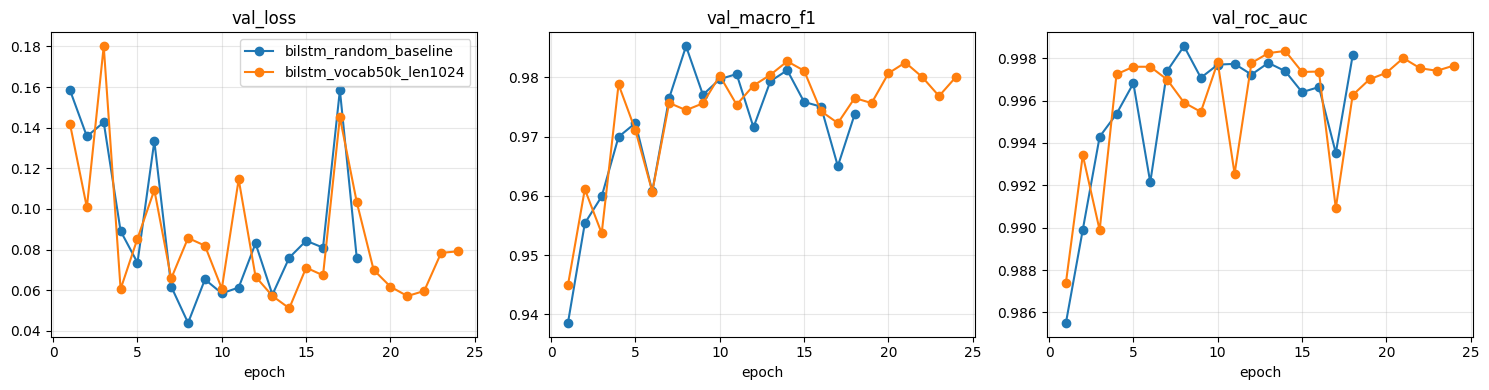

In [36]:
def plot_runs(run_names, metrics=("val_loss", "val_macro_f1", "val_roc_auc")):
    """Криві навчання кількох запусків на одному графіку."""
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4))
    axes = np.atleast_1d(axes)
    for name in run_names:
        history_path = OUT_DIR / "training_logs" / name / "history.csv"
        if not history_path.exists():
            print(f"Пропущено {name}: ще немає history.csv")
            continue
        history = pd.read_csv(history_path)
        for ax, metric in zip(axes, metrics):
            ax.plot(history["epoch"], history[metric], marker="o", label=name)
    for ax, metric in zip(axes, metrics):
        ax.set_xlabel("epoch")
        ax.set_title(metric)
        ax.grid(alpha=0.3)
    axes[0].legend()
    plt.tight_layout()
    plt.show()


# plot_runs(DISTILBERT_RUN)
# plot_runs(BILSTM_RUN)
# можна вказати списком

plot_runs(BILSTM_RUN + DISTILBERT_RUN)

# Синхронізація та допоміжні перевірки

In [21]:
from google.colab import userdata
import subprocess, os

REPO = "U-Karpcova/AI_Text_Detection"
SRC  = "/content/drive/MyDrive/ai_detect/runs"    # RUNS_ROOT
DST  = "/content/repo"

token = userdata.get("GITHUB_TOKEN")
if not os.path.exists(DST):
    subprocess.run(["git", "clone", f"https://{token}@github.com/{REPO}.git", DST], check=True)
else:
    subprocess.run(["git", "-C", DST, "pull", "--rebase"], check=True)

# тільки те що буде в дашборді (без ваг і smoke-запусків)
subprocess.run([
    "rsync", "-a", "--prune-empty-dirs",
    "--max-size=95m", "--exclude=_smoke",
    f"{SRC}/", f"{DST}/runs/",
], check=True)

def git(*args): subprocess.run(["git", "-C", DST, *args], check=True)
git("config", "user.email", "karpcova2004@gmail.com")
git("config", "user.name", "U-Karpcova")
git("add", "runs")
subprocess.run(["git", "-C", DST, "commit", "-m", "Update experiment logs"])  # без check: нічого комітити - не помилка
git("push")

# які файли було пропущено через розмір
big = subprocess.run(["find", SRC, "-type", "f", "-size", "+95M", "-not", "-path", "*/_smoke/*"],
                     capture_output=True, text=True).stdout.split()
print("Пропущено (завеликі для GitHub):", *big, sep="\n  ") if big else print("Усі файли <95 МБ — синхронізовано.")


Пропущено (завеликі для GitHub):
  /content/drive/MyDrive/ai_detect/runs/daigt/training_logs/distilbert_uncased/best_model.pt
  /content/drive/MyDrive/ai_detect/runs/daigt/training_logs/distilbert_lr3e-5/best_model.pt
  /content/drive/MyDrive/ai_detect/runs/daigt/training_logs/distilbert_lr5e-5/best_model.pt
  /content/drive/MyDrive/ai_detect/runs/daigt/training_logs/distilbert_len256/best_model.pt


In [22]:
# синхронізація чекпойнтів для трансформерів (збереження *.pt)
# Дашборд знаходить файл за цим шляхом, коли best_model.pt немає в самому репозиторії GitHub

from google.colab import userdata
from huggingface_hub import HfApi
from pathlib import Path

HF_REPO   = "Yuliana-K/ai-detect-checkpoints"             # id репозиторію моделей
RUNS_ROOT = Path("/content/drive/MyDrive/ai_detect/runs")      # RUNS_ROOT
MIN_MB    = 95                                                 # файли, великі для GitHub
PRIVATE   = False

api = HfApi(token=userdata.get("HF_TOKEN"))
api.create_repo(HF_REPO, repo_type="model", private=PRIVATE, exist_ok=True)

uploaded = set(api.list_repo_files(HF_REPO))
for ckpt in sorted(RUNS_ROOT.glob("*/training_logs/*/best_model.pt")):
    if ckpt.parts[-4].startswith("_") or ckpt.stat().st_size < MIN_MB * 1e6:
        continue
    scenario, run = ckpt.parts[-4], ckpt.parts[-2]
    path_in_repo = f"{scenario}/{run}/best_model.pt"
    if path_in_repo in uploaded:
        print(f"вже є: {path_in_repo}")
        continue
    print(f"завантажується {path_in_repo} ({ckpt.stat().st_size / 1e6:.0f} МБ)…")
    api.upload_file(path_or_fileobj=str(ckpt), path_in_repo=path_in_repo, repo_id=HF_REPO, repo_type="model")
print("Готово")


вже є: daigt/distilbert_len256/best_model.pt
завантажується daigt/distilbert_lr3e-5/best_model.pt (263 МБ)…


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...bert_lr3e-5/best_model.pt:   0%|          |  565kB /  263MB            

Validating                    :           |   0%            

завантажується daigt/distilbert_lr5e-5/best_model.pt (263 МБ)…


... (6 outputs left out)

New Data Upload               : |          |  0.00B /  0.00B            

  ...ert_uncased/best_model.pt:   0%|          |  575kB /  268MB            

Validating                    :           |   0%            

Готово


In [ ]:
def check_loader(loader, pad_idx, vocab_size):
    """Перевірка коректності dataloader для BiLSTM."""
    batch = next(iter(loader))
    input_ids, lengths, labels = batch["input_ids"], batch["lengths"], batch["labels"]

    print("input_ids shape:", input_ids.shape)
    print("lengths shape:", lengths.shape)
    print("labels shape:", labels.shape)
    print("\nПерші 5 довжин:", lengths[:5].tolist())
    print("Перші 5 міток:", labels[:5].tolist())

    # 1. Розмірності батча узгоджені
    assert input_ids.ndim == 2 and lengths.ndim == 1 and labels.ndim == 1
    assert input_ids.shape[0] == lengths.shape[0] == labels.shape[0]

    # 2. Padding має бути тільки після реальних токенів
    for i, length in enumerate(lengths.tolist()):
        assert length > 0
        assert torch.all(input_ids[i, :length] != pad_idx)
        assert torch.all(input_ids[i, length:] == pad_idx)

    # 3. Індекси мають бути в межах словника
    assert input_ids.min().item() >= 0
    assert input_ids.max().item() < vocab_size

    # 4. Мітки
    assert set(loader.dataset.labels).issubset({0, 1})

    print("\nУсі базові перевірки пройдено!")


def unknown_token_ratio(sequences, vocab):
    total = sum(len(seq) for seq in sequences)
    if total == 0:
        return 0.0
    unknown = sum(token_id == vocab.unk_idx for seq in sequences for token_id in seq)
    return unknown / total


def check_token_ratio(vocab, sequences, max_length, train_texts):
    """sequences = {"train": ..., "val": ..., "test": ...} — закодовані послідовності з get_bilstm_data."""
    for name in ("train", "val", "test"):
        print(f"UNK у {name}: {unknown_token_ratio(sequences[name], vocab):.2%}")
    print("\nСередня довжина train:", round(sum(map(len, sequences["train"])) / len(sequences["train"]), 1))
    print("Максимальна закодована довжина:", max(map(len, sequences["train"])))
    print("Текстів, довших за max_length:",
          sum(len(vocab.tokenize(text)) > max_length for text in train_texts))

In [ ]:
# Після запуску розділу BILSTM

_cfg = make_cfg(BILSTM, BILSTM_EXPERIMENTS["bilstm_random_baseline"])
_vocab, _seqs = get_bilstm_data(_cfg, SPLITS)
_loader = make_loader(TextDataset(_seqs["train"], get_labels(SPLITS)["train"]),
                      _cfg.batch_size, True, make_bilstm_collate(_vocab.pad_idx), _cfg.seed)
check_loader(_loader, _vocab.pad_idx, len(_vocab))
check_token_ratio(_vocab, _seqs, _cfg.max_length, SPLITS["train"]["text"])

input_ids shape: torch.Size([64, 512])
lengths shape: torch.Size([64])
labels shape: torch.Size([64])

Перші 5 довжин: [492, 55, 310, 512, 512]
Перші 5 міток: [0.0, 0.0, 1.0, 0.0, 0.0]

Усі базові перевірки пройдено!
UNK у train: 1.35%
UNK у val: 1.77%
UNK у test: 9.72%

Середня довжина train: 413.2
Максимальна закодована довжина: 512
Текстів, довших за max_length: 6416


Inference

In [ ]:
text = '''
The U.S. bombings thatended World War II didn’t mark theclose of atomic warfare.They were just the beginning.
The U.S. bombingsthat ended World War IIdidn’t mark the close ofatomic warfare. They werejust the beginning.
From 1945 to 2017, nuclear nationscarried out more than 2,000 explosive testsin the atmosphere, undergroundand underwater, mostly in remote places.
From 1945 to 2017,nuclear nations carried outmore than 2,000 explosivetests in the atmosphere,underground and underwater,mostly in remote places.
Larger circlesindicate places with many repeated tests.
Larger circlesindicate places withmany repeated tests.
Some of the atmospheric testswere magnitudes more powerful thanthe bombs dropped on Japan,sickening and displacing thousands.
Some of the atmospherictests were magnitudes morepowerful than the bombsdropped on Japan, sickeningand displacing thousands.
Their descendants — whocontinue to endure physical,psychological, economicand cultural fallout — are livingproof that nuclear weaponsshould never be testedagain. If only today’s leaderswould take heed.
Their descendants — whocontinue to endure physical,psychological, economicand cultural fallout — are livingproof that nuclear weaponsshould never be testedagain. If only today’s leaderswould take heed.
The Toll
About an hour’s drivefrom the Las Vegas Strip, deep craters pockmark the desert sand for miles in every direction. It’s here, amid the sunbaked flats, that the United States conducted 928 nuclear tests during the Cold War above and below ground. The site is mostly quiet now, and has been since 1992, when Washington halted America’s testing program.
There are growing fears this could soon change. As tensions deepen in America’s relations with Russia and China, satellite images reveal all three nations areactively expandingtheirnuclear testing facilities, cutting roads and digging new tunnels at long-dormant proving grounds, including in Nevada.
None of these nations have conducted a full-scale nuclear test since the 1990s. Environmental and health concerns pushed them to move the practice underground in the middle of the last century, before abandoning testing altogether at the end of the Cold War.
Each government insists it will not be the one to reverse the freeze. Russia and China have said little about the recent flurry of construction at their testing sites, but the United States emphasizes it’s merely modernizing infrastructure for subcritical tests, or underground experiments that test components of a weapon but fall short of a nuclear chain reaction.
The possibility of resuming underground nuclear testing has long loomed over the post-Cold War world. But only now do those fears seem worryingly close to being realized amid the growing animosity among the world powers, the construction at testing grounds and the development of a new generation of nuclear weapons.
As this pressure mounts, some experts fear that the United States could act first. Ernest Moniz, a physicist who oversaw the nation’s nuclear complex as energy secretary under President Barack Obama, said there’s increasing interest from members of Congress, the military and U.S. weapons laboratories to begin full-scale explosive tests once again. “Among the major nuclear powers, if there is a resumption of testing, it will be by the United States first,” Mr. Moniz said in a recent interview.
This article is part of the Opinion seriesAt the Brink,about the threat of nuclear weapons in an unstable world. Read the opening piecehere.
This article is part ofthe Opinion seriesAt the Brink,about the threat of nuclearweapons in an unstable world.Read the opening piecehere.
The Trump administrationprivately discussedconducting an underground test in hopes of coercing Russia and China into arms control talks in 2020, and this week his former national security adviser offered a possible preview of Mr. Trump’s second term bypublicly urginghim to restart the nuclear testing program. The Biden administration is adamant that technological advances have made it unnecessary to resume full-scale testing, butin Mayit began the first in a series of subcritical tests to ensure America’s modern nuclear warheads would still work as designed. These experiments fall within the United States’ promise not to violate the testing taboo.
A return to that earlier era is certain to have costly consequences. The United States and the Soviet Union might have narrowly avoided mutual destruction, but there was a nuclear war: The blitz of testing left a wake of illness, displacement and destruction, often in remote locations where marginalized communities had no say over what happened on their own land. Millions of people living in those places — Semipalatinsk, Kazakhstan; Reggane, Algeria; Montebello, Australia; the Republic of Kiribati — became unwitting casualties to an arms race run by a handful of rich, powerful nations.
The United States detonated the first underwater nuclear weapon in the Bikini Atoll, Marshall Islands, in 1946.
Many nuclear experts believe that a single explosive test by any of the major nuclear powers could lead to a resumption of testing among them all. And while the world is unlikely to return to the Cold War spectacle of billowing mushroom clouds from tests in the earth’s atmosphere, even a resumption of underground testing, which still can emit hazardous radiation, could expose new generations to environmental and health risks.
It would open a volatile chapter in the new nuclear age as we’re still trying to understand the fallout from the first one.
The Republic ofthe Marshall Islands Embassy is a modest, red brick building in a leafy Washington, D.C., neighborhood. Inside, a room on the first floor is packed with cardboard boxes and filing cabinets, each brimming with U.S. government documents detailing America’s nuclear testing program in the islands. It seems like a generous collation of history — until you open a box, pick up a page and see the endless blocks of text blacked out mostly for what the government claims are national security reasons.
While the Nevada test site hosted more nuclear detonations than any other place on the planet, the United States tested its largest bombs at the Pacific Proving Grounds. The 67 nuclear weapons tested in the Marshalls from 1946 to 1958 involved blasts hundreds of times more powerful than the American bomb that demolished Hiroshima, Japan.
The potential health risks of testing were known from the start of the U.S. nuclear weapons program. Five days after J. Robert Oppenheimer’s team covertly detonated the first atomic bomb in New Mexico in July 1945, a U.S. government memorandum was drawn up describing “the dust outfall from the various portions of the cloud was potentially a very serious hazard” for people living downwind of the desert test site.
And so when World War II ended and the nation’s rush to fine-tune its new weapon began, Washington looked for a remote location to test the bomb. The search ultimately turned up two spots: One was a 680-square-mile stretch of desert northwest of Las Vegas, in the region where Dr. Oppenheimer made the bomb. The other was much farther from home, in the middle of the Pacific Ocean.
In February 1946, just six months after the United States dropped two atomic bombs on Japan, a Navy officer appeared in the Marshall Islands, a collection of more than 1,000 islands scattered across 750,000 square miles between Hawaii and the Philippines. The United States had taken control of the islands from Japan during the war, and the military identified Bikini Atoll, a coral reef where people had lived for thousands of years, as an ideal testing ground.
After a Sunday afternoon church service, Commodore Ben Wyatt, the American military governor of the islands, made a religious appeal to the Bikini leader King Juda and his people, asking if they were willing to sacrifice their island for the welfare of all men. In truth, they had no choice: Preparations werealready underwayon the order of President Harry Truman.
Not long after, 167 Bikinians were ushered aboard a relocation ship and sent over 100 miles away to an island with scant vegetation and a lagoon full of poisonous fish. As they drifted toward their new home, they could see rising flames as American soldiers burned the huts and outrigger boats they left behind. Four months later, the U.S. military detonated two atomic bombs on Bikini Atoll. Though they planned to return, the Marshallese would never be able to safely live there again.
Unlike Dr. Oppenheimer’s first highly secretive atomic test, these explosions in the Pacific served as public spectacles. The military brought along journalists, politicians andreportedly18 tons of camera equipment and half of the world’s supply of motion picture film to record the events. The goal was to get attention — specifically, the Soviet Union’s attention — by spreading information and footage of these new wonder weapons.
The tests did more than that. They kicked off a generation of nuclear proliferation across the globe. One by one, each country with the money and the drive to compete started its own nuclear weapons program. And when they did, they took their cue from the United States and tested the devices in far-flung locations — and in many cases, their own territories. The Soviet Union tested its weapons in Kazakhstan. The French in Africa and Polynesia. China in Xinjiang. The British in Australia.
Britain conducted nuclear weaponstests and experiments in Australia from 1952to 1963. Carcinogenic plutonium releasedduring the program has been absorbed intothe soil and food chain over decades.
Britain conductednuclear weapons tests andexperiments in Australiafrom 1952 to 1963.Carcinogenic plutoniumreleased during theprogram has been absorbedinto the soil and foodchain over decades.
Karina Lester, who lives insouthern Australia, worries about theeffects on the land and her children.
Karina Lester, who livesin southern Australia, worriesabout the effects on the landand her children.
The nuclear powersmight have been the most technologically advanced countries in the world, but in hindsight, it’s clear they had little idea of what they were doing, and the health of the local populations was an afterthought, if a thought at all.
As tests continued at a breakneck pace, American scientists grew increasingly worried about the dangers posed by the weapons’ fallout. Chief among their fears was how much radioactive isotopes like strontium-90, formed in nuclear detonations, were being swept away on winds and falling back to earth through rain far beyond the remote blast areas onto farms and dairies where they could enter the food chain. Strontium-90, which is structurally similar to calcium and attaches to bones and teeth after being ingested, is known to cause cancer.
In the early 1950s, the Atomic Energy Commission, the U.S. agency overseeing nuclear weapons at the time, stationedroughly 150remote monitors at home and abroad to pick up signs of radiation. It also started a program to obtain “human samples” to test for strontium, according to adeclassifiedtranscriptfrom a 1955 meeting. “If anybody knows how to do a good job of body snatching, they will really be serving their country,” said Willard F. Libby, an agency commissioner at the time. Over the next several years, the U.S. government gatheredover 1,500 body partsfrom cadavers, many of them stillborn babies, from several countries without knowledge of the subject’s next of kin.
While the government pursued this science in the shadows, civilian studies were also underway. Teams at St. Louis University and the Washington University School of Dental Medicine collected around 320,000 baby teeth, mainly from the St. Louis area, that were donated by parents and guardians. They found that children born in 1963 had 50 times the level of strontium-90 in their teeth as children born in 1950. The initial results would later become the first major public study to raise the alarm on testing’s inherent risk to human health.
Even as this researchwas unfolding, the U.S. government pressed on with its testing in the Marshall Islands. On March 1, 1954, it conducted its largest test, code-named Castle Bravo. American weapon designers drastically underestimated the size of the weapon’s explosion by nearly threefold, a devastating miscalculation.
The device, which had 1,000 times the force of the bomb dropped on Hiroshima, was set off before dawn, sending a blinding flash across the sky for 250 miles or more above the Pacific. Three small islands were instantly vaporized. A mushroom cloud shot about 25 miles into the stratosphere, suctioning up 10 million tons of pulverized coral debris.
Within weeks, Marshallese living within 100 miles of the blast became weak and nauseated, developed weeping lesions and lost fistfuls of hair. The U.S. military evacuated more than 230 people to a U.S. Navy base on the nearby Kwajalein Atoll. Once they were there, men, women and children were interned at a camp and unwittingly enrolled in a secret U.S. government medical program calledProject 4.1.
The goal was to find out how radiation from weapons affects humans, something scientists couldn’t fully register inside a laboratory through animal experimentation. “While it is true that these people do not live, I would say, the way Westerners do — civilized people — it is nevertheless also true that these people are more like us than the mice,” said Merril Eisenbud, then the Atomic Energy Commission’s chief of health and safety, in a declassified transcript.
The aftermath was grim. The group suffered from widespread symptoms associated with acute radiation sickness. The rate of miscarriage and stillbirth among women exposed to the fallout wasroughly twicethat in unexposed women during the first four years after the Castle Bravo test. Babies were born with transparent skin and without bones — what the Marshallese midwives call jellyfish babies — and young children disproportionately developed thyroid abnormalities, including cancer, because of their size and metabolism.
Even with this kind of evidence in hand, science has reached only limited conclusions about how nuclear weapons testing affects individuals’ health. Researchers know that the last century’s atmospheric testing sent radioactive fallout across the world, affecting countless people. In the United States alone, astudy by the Centers for Disease Control and Preventionfound that every person in the continental United States who has been alive since 1951 has had some exposure to radioactive fallout from nuclear testing.
But startlingly little analysis or funding has gone into the long-term study of the descendants of people exposed to nuclear weapons radiation. Many descendants believe that their family’s exposure explains their own illnesses, but they are often left without the data to back up — or refute — their claims. It is difficult for medical experts to say definitively whether any individual’s cancer or illness is a direct result of radioactivity or something else, such as smoking or exposure to other harmful products throughout their lives. They can only say that radiation increases the risks. To many downwinders, as nuclear testing survivors are globally known, the dearth of information feels like further evidence of being sidelined by their respective governments.
What the existing studies do show is that where there have been nuclear tests, there have also been an unusually high number of people with health problems. In northeast Kazakhstan, where the last of 456 Soviet tests took place more than three decades ago,children near the test sitehave beenborn without limbsor developed cancer inhigher numbers than normal.Studiesof the exposed population show that elevated levels of serious illness persisted for two generations. Across French Polynesia — where France conducted nuclear tests over three decades — thyroid, blood and lung cancers have been prevalent.
Even today, descendants of nuclear test survivors fear passing illnesses onto future generations.
France tested nuclear weaponsin French Polynesia from 1966 to 1996.Facing worldwide protests andan international trade boycott, it finallyended its testing program.
France tested nuclearweapons in French Polynesiafrom 1966 to 1996.Facing worldwide protestsand an internationaltrade boycott, it finally endedits testing program.
Hinamoeura Morgant-Cross,born in Tahiti, is the fourth generationin her family to develop cancer.
Hinamoeura Morgant-Cross,born in Tahiti, is thefourth generation in her familyto develop cancer.
After Castle Bravo,the evidence was unmistakable: A single bomb blowing up on one side of the globe could touch everyone on the other. The fallout from the test did not harm only the Marshallese. It also sickened fishermen aboard a nearby Japanese fishing ship and stoked widespread fears of contamination in Japanese fish stocks, retraumatizing Japan less than a decade after American bombs killed anestimated 200,000people in Hiroshima and Nagasaki. Within a month, traces of falloutstretchedfrom Asia to Europe. The massive U.S. experiment became a global news story, and calls for a global testing moratorium began almost immediately.
At the time of the Castle Bravo test, all three nuclear nations — the United States, the Soviet Union and Britain — were actively testing their weapons above ground. Within 10 years, the three superpowers signed the 1963 Limited Test Ban Treaty, which officially confined them to testing underground. France continued atmospheric testing until 1974, and China continued until 1980.
In underground tests, the nuclear explosions took place inside a canister placed within a vertical hole drilled more than 1,000 feet into the earth. Miles of electrical cables connected to the canister relayed information on the blast to recording stations on the surface. While that process avoided widespread radioactive fallout, it could still contaminate groundwater and cause so-called venting incidents, in which radioactive debris leaked from below ground into the air.
As a result, in 1996, the world’s largest nuclear powers signed the Comprehensive Nuclear Test Ban Treaty, which banned all nuclear explosions above and below ground and established a global monitoring system to detect any tests that take place. India and Pakistan, which did not sign the treaty, both held underground tests in 1998, but only North Korea has conducted them since.
For years, test survivorsacross the world have fought for compensation for what these experiments cost them: their homes, their health, their culture and their community. Spurred by the inaction among world powers, many individuals from these communities are outspoken activists at the forefront of the global disarmament movement. They helped create the 2021 Treaty on the Prohibition of Nuclear Weapons, signed by 93 countries, which bans the possession, use and testing of nuclear weapons.
Despite this mobilization, there are only a handful of examples of nuclear weapon states compensating downwinders for exploding the world’s biggest bombs near their neighborhoods and ancestral homelands. France has acknowledged its “debt” to Polynesians over nuclear testing, and it created a commission in 2010 to evaluate nuclear testing victim compensation claims, but it has never apologized. Neither has Britain, nor has it established means of compensation.
The Marshallese have had slightly more success than others. While the United States has never issued an apology for displacing thousands of people and rendering parts of the nation uninhabitable, it paid the Marshallese $150 million in the 1980s for what the U.S. governmentcalls“a full and final” settlement of all claims related to the testing program. Since then, it has allocated hundreds of millions of dollars for education, health care, the environment and infrastructure,according to the U.S. government.
But it’s not enough. The Marshallese government has claimed roughly $3 billion in uncompensated damages.
As part of a 1986 compact, the United States gave control of the islands back to the Marshallese, while the U.S. military kept control of a sprawling missile-test site on Kwajalein Atoll. The compact also gave all Marshallese permission to live and work in the United States indefinitely without visas.
The deal has been a welcome development for the growing number of Marshallese who have simply given up on building a life back home, where unemployment and poverty remain pervasive, and good schools and quality health care are scarce. Small Marshallese communities are now scattered across the United States, including in Hawaii, California, Washington and Oregon. But the largest population of Marshallese in the world outside the islands is in a rural area surrounding the northwest corner of Arkansas, mainly in a small city called Springdale. So many Marshallese live in this agricultural industrial heartland — about 20,000 by one count — they call it the Springdale Atoll.
It began in the 1980s when a Marshallese man named John Moody landed a job in one of the area’s sprawling poultry plants. Soon more people started to arrive from the islands as news spread about the jobs, better doctors and schools. Today, when you’re in Springdale, it doesn’t take long to spot signs of the community: the Blue Pacific Mart convenience store, the KMRW 98.9 Marshallese radio station and dozens of homespun Marshallese churches.
Off Emma Avenue, the city’s main street, in a single-story, L-shaped building, Benetick Kabua Maddison runs the Marshallese Educational Initiative. Mr. Maddison, 29, took over the nonprofit in 2022 to raise awareness about the islands’ culture and nuclear testing legacy. His team teaches community members how the tests drove so many people to leave the islands and how the testing program affected their health.
The populations of entire islandswere permanently displaced whenAmerica decided to test its weaponson the Marshall Islands, which itcontrolled after World War II. The testsleft some of the islands, includingBikini Atoll, uninhabitable.
The populations of entireislands were permanentlydisplaced when Americadecided to test its weapons onthe Marshall Islands, which itcontrolled after World War II.The tests left some ofthe islands, including BikiniAtoll, uninhabitable.
Benetick Kabua Maddison’sfamily was among them. He nowlives in Arkansas.
Benetick Kabua Maddison’sfamily was among them.He now lives in Arkansas.
Diabetes rates among the Marshallese globally are now400 percentas high as for the general U.S. population. When Covid-19 came to Springdale in 2020, it hit the Marshallese community — like other groups across the states with high rates of noncommunicable diseases — disproportionately hard. Estimated to represent about 2 percent of the local population in northwest Arkansas, the Marshallese accounted for38 percent of the deathsthere during the pandemic’s first four months.
It was a stark reminder of nuclear testing’s complex and far-reaching legacy. “The Marshallese are living proof that nuclear weapons must never be used or tested again,” Mr. Maddison said.
Few places on earthcan still convey the raw power of nuclear weapons like the Nevada Test Site. From a wooden observation platform, you can look out over a crater 320 feet deep and a quarter-mile wide created by a 104-kiloton device detonated underground in July 1962. It’s just one of the many man-made pits dotting the 1,375-square-mile proving grounds that are roughly the size of Rhode Island.
Today a sprawling tunnel network under the site, originally excavated in the 1960s for an underground nuclear test, is being transformed into a subterranean research laboratory to host the subcritical nuclear experiments that started again in May. American scientists hope the roughly $2.5 billion investment in new diagnostic, monitoring and computing equipment will help them gain further insights into exactly what happens inside a thermonuclear explosion, beyond what was learned from the live-fire tests that ended in the 1990s.
Knowing the increased activity will raise eyebrows, the Biden administrationhas publicly floated a planto Russia and China to install radiation detection equipment near one another’s subcritical experiments to ensure an atomic chain reaction does not occur. A senior administration official says the United States is even considering inviting international observers or livestreaming the experiments to head off any skepticism of their intentions.
Mistrust is already running deep. While all nuclear nations that signed the Comprehensive Nuclear Test Ban Treaty have appeared to observe it in practice, both China and the United States failed to ratify the treaty because of internal political challenges — and the desire to keep their options for future testing open without running afoul of international law.
In November, Russia rescinded its ratification, citing the United States’ failure to ratify the pact. President Vladimir Putin intimated that if Washington tested again, Moscow would follow with one of its own. He took another step in that directionon June 7,saying that Russia could test a nuclear weapon but that there was no need at the present time.
For now in Nevada, roughly 1,000 feet above the underground lab, remnants from the last nuclear era — cables, containers and equipment — sit idle in a fenced-off area atop the desert flats. They are still stored on-site and on standby, upon government mandate, to be ready for use should a president ever issue the order for explosive testing to begin once again.
The world can’t afford to restart this dangerous cycle. We are still wrestling with the damage wrought by testing nuclear weapons in our past. It shouldn’t be a part of our future.
W.J. Hennigan writes about national security issues for Opinion from Washington, D.C. He has reported from more than two dozen countries, covering war, the arms trade and the lives of U.S. service members. Additional reporting by Spencer Cohen.
Photographs by Ike Edeani. Top grid of testing survivors and descendants:Tamatoa Tepuhiarii, Aigerim Yelgeldy, Adiya Akhmer, Raygon Jacklick, Benetick Kabua Maddison, Karina Lester, Hinamoeura Morgant-Cross, Kairo Langrus, Aigerim Seitenova, Ereti Tekabaia, Matthew John and Mere Tuilau.Tamatoa Tepuhiarii, Adiya Akhmer, Raygon Jacklick, Benetick Kabua Maddison, Hinamoeura Morgant-Cross, Aigerim Yelgeldy, Aigerim Seitenova, Matthew John, Kairo Langrus, Karina Lester, Ereti Tekabaia and Mere Tuilau
Video produced by Amanda Su, Elliot deBruyn and Jonah M. Kessel. Archival videos: Établissement de communication et de production audiovisuelle de la Défense, Grinberg, Paramount, Pathe Newsreels, The Associated Press, Getty Images.
Graphics by Gus Wezerek. Testing locations for the map fromReutersand the Stockholm International Peace Research Institute.
This Times Opinion series is funded through philanthropic grants from theCarnegie Corporation of New York,Outrider Foundationand theProspect Hill Foundation. Funders have no control over the selection or focus of articles or the editing process and do not review articles before publication. The Times retains full editorial control.
'''

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cpu


In [ ]:
def load_bilstm_for_inference(run_dir, device):
    run_dir = Path(run_dir)
    meta = json.loads(
        (run_dir / "config.json").read_text(encoding="utf-8")
    )

    if meta["model_type"] != "bilstm":
        raise ValueError(
            f"{run_dir.name} is not a BiLSTM run: "
            f"{meta['model_type']}"
        )

    cfg = BiLSTMConfig(**meta["config"])

    vocab = Vocabulary.from_itos(
        json.loads(
            (run_dir / "vocab.json").read_text(encoding="utf-8")
        ),
        cfg.vocab_min_freq,
        cfg.vocab_max_size,
    )

    model = make_bilstm(cfg, vocab).to(device)
    checkpoint_path = run_dir / "best_model.pt"

    # завантажити найкращі ваги
    state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(state_dict)

    model.eval()

    return model, vocab, cfg


def predict_bilstm(text, model, vocab, cfg, device):
    sequence = encode_texts(
        [text],
        vocab,
        max_length=cfg.max_length,
    )[0]

    # Batch з одного прикладу
    input_ids = torch.tensor(
        [sequence],
        dtype=torch.long,
        device=device,
    )

    lengths = torch.tensor(
        [len(sequence)],
        dtype=torch.long,
    )

    # Inference без обчислення градієнтів
    with torch.no_grad():
        logits = model(input_ids, lengths)

        # BCEWithLogitsLoss означає, що модель повертає logits
        probability = torch.sigmoid(logits).item()

    prediction = int(probability >= 0.5)

    return {
        "prediction": prediction,
        "probability": probability,
    }


In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
run_dir = Path("/content/drive/MyDrive/ai_detect/runs/defactify/training_logs/bilstm_glove_frozen")

model, vocab, cfg = load_bilstm_for_inference(
        run_dir, DEVICE)

result = predict_bilstm(
        text,
        model,
        vocab,
        cfg,
        DEVICE)

print(result)


{'prediction': 0, 'probability': 5.282640813675243e-06}


In [ ]:
import sklearn
import numpy as np

print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)

scikit-learn: 1.6.1
NumPy: 2.4.6
